# Chain-level digital twin — experiments

A single notebook for **Mixing → Coating/Drying → Calendering → Electrochemical**.
Run from top to bottom once in **LaptopEnv** (the existing `myenv` kernel).
Then change the inputs or experiment settings and rerun the relevant sections.
Everything needed to execute the framework is defined here; there are no imports
from the supporting Python project.

The RF-labelled chain keeps all supplied tree models, including ExtraTrees.
The DNN chain uses its own networks, preprocessors and target inverses.
RF importance uses permutation feature importance (PFI); DNN importance uses
forward finite differences. Both recompute the whole chain after changing an input.

**Sections:** 1 Inputs · 2 Orchestration · 3 RF models · 4 DNN models ·
5 Simulation · 6 Validation · 7 Feedback · 8 Parametric simulation ·
9 Correlations and selections · 10 RF PFI · 11 DNN finite differences ·
12 Sensitivity with feedback · 13 Execution checks · Appendix indexed mathematics.

Model weights and source workbooks are read only. Exports and runtime caches stay
inside `codex_work/`. The large original orchestration cell is folded; expand it
to inspect the unchanged mathematical implementation.


## 1. Inputs and environment

Select LaptopEnv before running this cell. Normally `PROJECT_DIR=None` works
because Jupyter starts in this folder. Set it to this folder's full path if needed.
`SAVE_RESULTS=False` keeps experiments in memory without exporting files.


The default input is `test_aggregated_deterministic.xlsx` (unseen-data run). Switch to `train_valid_aggregated_deterministic.xlsx` for the familiar-data run. `RUN_LABEL` follows the input filename and keeps all exported results separate. The training/validation aggregate remains the fixed reference for finite-difference input scales in both runs. No refitting occurs.


In [ ]:
from pathlib import Path
from copy import deepcopy, copy
import os
import sys
import json
import hashlib
import zipfile
import warnings
import numpy as np
import pandas as pd
from joblib import load
from IPython.display import display, Image, FileLink

PROJECT_DIR = None             # e.g. r"C:\...\Framework-level"
SAVE_RESULTS = True
RUN_LABEL = "interactive"             # set from DATA_FILE in the next section
ROOT = (Path(PROJECT_DIR) if PROJECT_DIR else Path.cwd()).resolve()
if not (ROOT / "best models").is_dir():
    raise FileNotFoundError("Set PROJECT_DIR to the Framework-level folder.")
WORK = ROOT / "codex_work"
WORK.mkdir(exist_ok=True)
os.environ["KERAS_HOME"] = str(WORK / ".runtime_cache/keras")
os.environ["MPLCONFIGDIR"] = str(WORK / ".runtime_cache/matplotlib")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

def project_path(path):
    candidate = Path(path)
    candidate = (candidate if candidate.is_absolute() else ROOT / candidate).resolve()
    if not candidate.is_relative_to(ROOT):
        raise ValueError("Keep input and output paths inside Framework-level.")
    return candidate

def result_path(path):
    candidate = project_path(Path("codex_work/results") / RUN_LABEL / path)
    candidate.parent.mkdir(parents=True, exist_ok=True)
    return candidate

def export_table(frame, path, index=False):
    if SAVE_RESULTS:
        frame.to_csv(result_path(path), index=index)

def show_saved_plot(path):
    if path is not None:
        display(Image(filename=str(path)))

print("Folder:", ROOT)
print("Python:", sys.executable)

CHART_COLORS = {"Measured": "#1f77b4", "RF": "#2ca02c", "DNN": "#d62728"}


Folder: C:\Users\Tavako_M\OneDrive - University of Warwick\Workstation\BATTWIN Project\Paper1-Formal framework\New_upstream_models\Framework-level
Python: C:\Users\Tavako_M\OneDrive - University of Warwick\Workstation\LaptopEnv\Scripts\python.exe


**Edit the data here.** Choose a workbook or CSV inside this folder, or replace
`df_input` with your own DataFrame. Every row is one chain execution. The model
sections below show required inputs and exact feature connections.

Keep measured target columns in `df_input` if you want validation or PFI.
They are kept separate from the model inputs. `reference_data` only supplies
input standard deviations for optional scaling of DNN sensitivity; it fits nothing.


In [ ]:
DATA_FILE = "test_aggregated_deterministic.xlsx"                    # change to another local dataset
REFERENCE_FILE = "train_valid_aggregated_deterministic.xlsx"
RUN_LABEL = Path(DATA_FILE).stem           # each dataset gets its own results folder

def read_data(filename):
    path = project_path(filename)
    frame = pd.read_csv(path) if path.suffix.lower() == ".csv" else pd.read_excel(path)
    if frame.columns.duplicated().any():
        raise ValueError("Input data contains duplicate column names.")
    return frame

df_input = read_data(DATA_FILE)
reference_data = read_data(REFERENCE_FILE)
# Example edits (uncomment and change as needed):
# df_input = df_input.iloc[:10].copy()
# df_input.loc[:, "Discharge rate (*C)"] = 1.0
# df_input = pd.DataFrame([your_input_dictionary])

print(f"Input: {len(df_input)} rows, {len(df_input.columns)} columns")
print("Missing values:", int(df_input.isna().sum().sum()))
print("Reference rows:", len(reference_data))
display(df_input.head())

print("Results:", WORK / "results" / RUN_LABEL)


Input: 38 rows, 30 columns
Missing values: 0
Reference rows: 291


,Electrode type,Chemistry,Am/total weight%,Conductive additive type,Conductive additive/total weight %,Binder1 type,Binder1/total weight %,Binder2 (Thickener) type,Binder2 (thickener)/total weight %,Solvent,...,Slurry density g/cm3,Calendering Roll speed(m/min),Calendaring Roll temp,Calendaring Gap (um),Mass loading dry (mg/cm2),Calendered thickness (um),Calendered porosity (%),Discharge rate (*C),Gravimetric capacity (mA h/g),Volumetric capacity (mA h/cm3)
0,Cathode,NMC622,64.32,C65,1.34,PVDF,1.34,"""none""",0.00,NMP,...,3.260899,0.5,85,58.973455,18.403256,62.000000,32.203532,0.2,160.118389,472.121304
1,Cathode,NMC622,64.32,C65,1.34,PVDF,1.34,"""none""",0.00,NMP,...,3.335769,0.5,85,59.410133,18.539526,59.000000,30.123232,0.2,159.137014,483.589583
2,Anode,GRA,48.88,C65,0.52,SBR,1.56,CMC,1.04,water,...,1.600000,1.0,100,44.000000,8.568808,65.233333,39.125619,0.2,233.515926,293.004570
3,Anode,GRA,48.88,C65,0.52,SBR,1.56,CMC,1.04,water,...,1.600000,1.0,100,44.000000,10.121783,62.600000,25.068215,0.2,219.167441,316.376613
4,Anode,GRA,48.88,C65,0.52,SBR,1.56,CMC,1.04,water,...,1.600000,1.0,100,49.000000,11.902432,74.266667,25.728310,0.2,222.507669,341.011284


Results: C:\Users\Tavako_M\OneDrive - University of Warwick\Workstation\BATTWIN Project\Paper1-Formal framework\New_upstream_models\Framework-level\codex_work\results\test_aggregated_deterministic


## 2. Orchestration and feature names

The original named feature-store implementation is retained without changing
its function or class bodies. Each stage reads the current feature store and
writes its own predicted outputs; later stages read those predictions.
Feedback memory stays fixed during one item and updates for the next item:

$$e_i = KPI_i - KPI_{target},\qquad \zeta_{i+1} = \zeta_i + g e_i.$$

The original indexed `W_k`, `Pi_k` and sensitivity propagation are included in
the appendix. Expand the folded cell below to inspect the named implementation.


In [ ]:
from copy import deepcopy

import numpy as np

def default_objective_from_kpi(features_final, kpi_key):
    """
    Default objective: J = KPI value.

    Parameters
    ----------
    features_final : dict
        Final feature store after chain execution
    kpi_key : str
        Key of KPI in features_final

    Returns
    -------
    float
        KPI value
    """
    if kpi_key not in features_final:
        raise KeyError(f"KPI key '{kpi_key}' not found in final features.")
    return float(features_final[kpi_key])

def is_numeric_scalar(x):
    """
    Check whether x behaves like a numeric scalar for perturbation purposes.
    """
    return isinstance(x, (int, float, np.integer, np.floating))

def proportional_feedback_update(zeta_dict, error, gains, target_stage_name):
    """
    Update stage-specific feedback memory using a proportional law.

    Parameters
    ----------
    zeta_dict : dict
        Current feedback memory
    error : float
        KPI error = KPI_current - KPI_target
    gains : dict
        Nested dict of gains per stage and feedback key
    target_stage_name : str
        Which stage feedback block is updated

    Returns
    -------
    dict
        Updated feedback memory
    """
    zeta_next = deepcopy(zeta_dict)

    if target_stage_name in zeta_next and target_stage_name in gains:
        for key, gain in gains[target_stage_name].items():
            if key in zeta_next[target_stage_name]:
                zeta_next[target_stage_name][key] += gain * error

    return zeta_next

class NamedStateSpaceLine:
    """
    Named-feature hybrid state-space framework.

    Main methods
    ------------
    compile()
        Check that stage names are unique.

    simulate_item(...)
        Run one item through the whole chain.

    simulate_items(...)
        Run many items with optional delayed feedback.

    sensitivity_one_item(...)
        Finite-difference sensitivity analysis for one item.

    sensitivity_items(...)
        Finite-difference sensitivity analysis for many items,
        with optional delayed feedback between items.
    """

    def __init__(self):
        self.chain_def = []
        self.compiled = False

    def load_sequence(self, chain_definition):
        """
        Load ordered chain definition.
        """
        self.chain_def = chain_definition

    def compile(self):
        """
        Compile simple structural checks.
        """
        stage_names = [stage["name"] for stage in self.chain_def]
        if len(stage_names) != len(set(stage_names)):
            raise ValueError("Stage names must be unique.")
        self.compiled = True

    def get_required_input_columns(self):
        """
        Return the set of columns required in the ORIGINAL input dataframe
        before stage-generated outputs are added.

        Each stage declares 'required_input_columns', excluding columns that
        are expected to be produced by upstream stages.
        """
        required = set()
        for stage in self.chain_def:
            stage_required = stage.get("required_input_columns", [])
            required.update(stage_required)
        return sorted(required)

    def validate_input_dataframe(self, df_input):
        """
        Validate that the input dataframe contains all required base columns.
        """
        required_cols = self.get_required_input_columns()
        missing_cols = [c for c in required_cols if c not in df_input.columns]

        if missing_cols:
            raise ValueError(
                "Input dataframe is missing required columns:\n"
                + "\n".join(f"  - {c}" for c in missing_cols)
            )

    def simulate_item(self, row_features, zeta_dict=None):
        """
        Simulate one item through the whole chain.

        Parameters
        ----------
        row_features : dict
            One input row converted to a dictionary
        zeta_dict : dict or None
            Stage-specific feedback memory

        Returns
        -------
        dict
            {
                "features_final": final evolving feature store,
                "stage_outputs": list of stage outputs,
                "zeta_used": feedback memory used for this item
            }
        """
        if not self.compiled:
            raise RuntimeError("Framework must be compiled before simulation.")

        if zeta_dict is None:
            zeta_dict = {}

        features = deepcopy(row_features)
        stage_outputs = []

        for stage in self.chain_def:
            stage_name = stage["name"]
            func = stage["func"]
            control = stage.get("control", {})
            theta = stage.get("theta", {})
            zeta_stage = deepcopy(zeta_dict.get(stage_name, {}))

            y_dict = func(
                features=features,
                zeta=zeta_stage,
                control=control,
                theta=theta,
            )

            if not isinstance(y_dict, dict):
                raise TypeError(f"Stage '{stage_name}' must return a dict.")

            # Write outputs back into the global named feature store
            features.update(y_dict)

            stage_outputs.append({
                "stage_name": stage_name,
                "outputs": deepcopy(y_dict),
            })

        return {
            "features_final": features,
            "stage_outputs": stage_outputs,
            "zeta_used": deepcopy(zeta_dict),
        }

    def simulate_items(
        self,
        df_input,
        use_feedback=False,
        zeta_init=None,
        kpi_key=None,
        kpi_target=None,
        feedback_gains=None,
        feedback_stage_name=None,
        row_id_column=None,
    ):
        """
        Simulate multiple rows / items.

        Parameters
        ----------
        df_input : pd.DataFrame
            Input dataframe. Each row is one item / chain execution.
        use_feedback : bool
            If True, delayed feedback is enabled.
        zeta_init : dict or None
            Initial feedback memory.
        kpi_key : str or None
            Final feature key used as KPI.
        kpi_target : float or None
            KPI target.
        feedback_gains : dict or None
            Gains for proportional feedback update.
        feedback_stage_name : str or None
            Which stage feedback block is updated.
        row_id_column : str or None
            Optional row identifier column.

        Returns
        -------
        list of dict
            History of all item simulations.
        """
        if not self.compiled:
            raise RuntimeError("Framework must be compiled before simulation.")

        self.validate_input_dataframe(df_input)

        if zeta_init is None:
            zeta_init = {}

        if feedback_gains is None:
            feedback_gains = {}

        if use_feedback:
            if kpi_key is None:
                raise ValueError("kpi_key must be provided when use_feedback=True.")
            if kpi_target is None:
                raise ValueError("kpi_target must be provided when use_feedback=True.")
            if feedback_stage_name is None:
                raise ValueError("feedback_stage_name must be provided when use_feedback=True.")

        zeta_current = deepcopy(zeta_init)
        history = []

        for i, (_, row) in enumerate(df_input.iterrows(), start=1):
            row_features = row.to_dict()

            result = self.simulate_item(
                row_features=row_features,
                zeta_dict=zeta_current if use_feedback else {},
            )

            features_final = result["features_final"]
            stage_outputs = result["stage_outputs"]

            kpi_value = None
            error = None
            zeta_next = deepcopy(zeta_current) if use_feedback else {}

            if use_feedback:
                if kpi_key not in features_final:
                    raise KeyError(f"KPI key '{kpi_key}' not found in final feature store.")

                kpi_value = float(features_final[kpi_key])
                error = kpi_value - float(kpi_target)

                zeta_next = proportional_feedback_update(
                    zeta_dict=zeta_current,
                    error=error,
                    gains=feedback_gains,
                    target_stage_name=feedback_stage_name,
                )

            history.append({
                "item_index": i,
                "row_id": row_features.get(row_id_column) if row_id_column else None,
                "features_final": deepcopy(features_final),
                "stage_outputs": deepcopy(stage_outputs),
                "kpi_key": kpi_key if use_feedback else None,
                "kpi_value": kpi_value,
                "kpi_target": float(kpi_target) if (use_feedback and kpi_target is not None) else None,
                "error": error,
                "zeta_used": deepcopy(zeta_current) if use_feedback else {},
                "zeta_next": deepcopy(zeta_next) if use_feedback else {},
            })

            if use_feedback:
                zeta_current = zeta_next

        return history

    def sensitivity_one_item(
        self,
        row_features,
        zeta_dict=None,
        sensitivity_columns=None,
        kpi_key=None,
        objective_fn=None,
        epsilon=1e-5,
    ):
        """
        Finite-difference sensitivity analysis for one item.

        Parameters
        ----------
        row_features : dict
            One input row as a feature dictionary.
        zeta_dict : dict or None
            Feedback memory for this item. Treated as FIXED during sensitivity analysis.
        sensitivity_columns : list of str
            Numeric input columns to perturb.
        kpi_key : str or None
            KPI key used if objective_fn is not provided.
        objective_fn : callable or None
            Optional custom scalar objective:
                J = objective_fn(features_final)
        epsilon : float
            Perturbation size for finite differences.

        Returns
        -------
        dict
            {
                "base_features_final": ...,
                "base_stage_outputs": ...,
                "J_base": ...,
                "d_eta_final": {input_col: {feature_key: derivative}},
                "dJ": {input_col: derivative}
            }
        """
        if not self.compiled:
            raise RuntimeError("Framework must be compiled before sensitivity analysis.")

        if zeta_dict is None:
            zeta_dict = {}

        if sensitivity_columns is None or len(sensitivity_columns) == 0:
            raise ValueError("sensitivity_columns must be a non-empty list.")

        # Base simulation
        base_result = self.simulate_item(
            row_features=deepcopy(row_features),
            zeta_dict=deepcopy(zeta_dict),
        )

        base_features_final = base_result["features_final"]
        base_stage_outputs = base_result["stage_outputs"]

        if objective_fn is not None:
            J_base = float(objective_fn(base_features_final))
        else:
            if kpi_key is None:
                raise ValueError("Provide either objective_fn or kpi_key.")
            J_base = default_objective_from_kpi(base_features_final, kpi_key)

        # Finite-difference derivatives
        d_eta_final = {}
        dJ = {}

        for col in sensitivity_columns:
            if col not in row_features:
                raise KeyError(f"Sensitivity column '{col}' not found in row_features.")

            base_value = row_features[col]

            if not is_numeric_scalar(base_value):
                raise TypeError(
                    f"Column '{col}' is not numeric. "
                    "Finite-difference sensitivity is only supported for numeric columns."
                )

            perturbed_row = deepcopy(row_features)
            perturbed_row[col] = float(base_value) + epsilon

            pert_result = self.simulate_item(
                row_features=perturbed_row,
                zeta_dict=deepcopy(zeta_dict),
            )

            pert_features_final = pert_result["features_final"]

            # d(eta_final)/d(col)
            feature_sens = {}
            for key, base_val in base_features_final.items():
                pert_val = pert_features_final.get(key, base_val)

                if is_numeric_scalar(base_val) and is_numeric_scalar(pert_val):
                    feature_sens[key] = (float(pert_val) - float(base_val)) / epsilon

            d_eta_final[col] = feature_sens

            # dJ/d(col)
            if objective_fn is not None:
                J_pert = float(objective_fn(pert_features_final))
            else:
                J_pert = default_objective_from_kpi(pert_features_final, kpi_key)

            dJ[col] = (J_pert - J_base) / epsilon

        return {
            "base_features_final": deepcopy(base_features_final),
            "base_stage_outputs": deepcopy(base_stage_outputs),
            "J_base": J_base,
            "d_eta_final": d_eta_final,
            "dJ": dJ,
        }

    def sensitivity_items(
        self,
        df_input,
        sensitivity_columns,
        use_feedback=False,
        zeta_init=None,
        kpi_key=None,
        kpi_target=None,
        feedback_gains=None,
        feedback_stage_name=None,
        objective_fn=None,
        epsilon=1e-5,
        row_id_column=None,
    ):
        """
        Finite-difference sensitivity analysis over multiple items.

        If feedback is enabled:
            - zeta is updated sequentially between items
            - during sensitivity analysis of one item, zeta is treated as fixed

        Parameters
        ----------
        df_input : pd.DataFrame
            Input rows to simulate
        sensitivity_columns : list of str
            Numeric columns to perturb
        use_feedback : bool
            If True, delayed feedback is enabled between items
        zeta_init : dict or None
            Initial feedback memory
        kpi_key : str or None
            KPI key used for default objective and feedback
        kpi_target : float or None
            KPI target used for feedback
        feedback_gains : dict or None
            Gains for feedback law
        feedback_stage_name : str or None
            Stage block to update in zeta
        objective_fn : callable or None
            Optional custom scalar objective
        epsilon : float
            Finite-difference perturbation
        row_id_column : str or None
            Optional row identifier

        Returns
        -------
        list of dict
            Sensitivity history item by item
        """
        if not self.compiled:
            raise RuntimeError("Framework must be compiled before sensitivity analysis.")

        self.validate_input_dataframe(df_input)

        if zeta_init is None:
            zeta_init = {}

        if feedback_gains is None:
            feedback_gains = {}

        if use_feedback:
            if kpi_key is None:
                raise ValueError("kpi_key must be provided when use_feedback=True.")
            if kpi_target is None:
                raise ValueError("kpi_target must be provided when use_feedback=True.")
            if feedback_stage_name is None:
                raise ValueError("feedback_stage_name must be provided when use_feedback=True.")

        zeta_current = deepcopy(zeta_init)
        history = []

        for i, (_, row) in enumerate(df_input.iterrows(), start=1):
            row_features = row.to_dict()

            sens_result = self.sensitivity_one_item(
                row_features=row_features,
                zeta_dict=deepcopy(zeta_current) if use_feedback else {},
                sensitivity_columns=sensitivity_columns,
                kpi_key=kpi_key,
                objective_fn=objective_fn,
                epsilon=epsilon,
            )

            features_final = sens_result["base_features_final"]

            kpi_value = None
            error = None
            zeta_next = deepcopy(zeta_current) if use_feedback else {}

            if use_feedback:
                if kpi_key not in features_final:
                    raise KeyError(f"KPI key '{kpi_key}' not found in final feature store.")

                kpi_value = float(features_final[kpi_key])
                error = kpi_value - float(kpi_target)

                zeta_next = proportional_feedback_update(
                    zeta_dict=zeta_current,
                    error=error,
                    gains=feedback_gains,
                    target_stage_name=feedback_stage_name,
                )

            history.append({
                "item_index": i,
                "row_id": row_features.get(row_id_column) if row_id_column else None,
                "features_final": deepcopy(features_final),
                "J_base": sens_result["J_base"],
                "dJ": deepcopy(sens_result["dJ"]),
                "d_eta_final": deepcopy(sens_result["d_eta_final"]),
                "zeta_used": deepcopy(zeta_current) if use_feedback else {},
                "zeta_next": deepcopy(zeta_next) if use_feedback else {},
                "kpi_value": kpi_value,
                "kpi_target": float(kpi_target) if (use_feedback and kpi_target is not None) else None,
                "error": error,
            })

            if use_feedback:
                zeta_current = zeta_next

        return history


**Physical outputs and model input alignment.** The combined model replaces
separate coating and drying stages. Electrochemical prediction adds the two
capacity outputs. This cell defines their names and protects measured outputs
from being supplied as base inputs.


In [ ]:
VISCOSITY = "Viscosity (Pa.s)"

MASS = "Mass loading dry (mg/cm2)"

DRY_THICKNESS = "Dry Coating Thickness (\u00b5m)"

DRY_POROSITY = "Dried Porosity"

CAL_THICKNESS = "Calendered thickness (um)"

CAL_POROSITY = "Calendered porosity (%)"

GRAVIMETRIC = "Gravimetric capacity (mA h/g)"

VOLUMETRIC = "Volumetric capacity (mA h/cm3)"

STAGE_OUTPUTS = {
    "Mixing": [VISCOSITY],
    "CoatingDrying": [MASS, DRY_THICKNESS, DRY_POROSITY],
    "Calendering": [CAL_THICKNESS, CAL_POROSITY],
    "Electrochemical": [GRAVIMETRIC, VOLUMETRIC],
}

OUTPUT_COLUMNS = [c for outputs in STAGE_OUTPUTS.values() for c in outputs]

MEASURED_OUTPUTS = [MASS, CAL_THICKNESS, CAL_POROSITY, GRAVIMETRIC, VOLUMETRIC]

CATEGORICAL_COLUMNS = [
    "Electrode type", "Chemistry", "Conductive additive type", "Binder1 type",
    "Binder2 (Thickener) type", "Solvent", "Dispersent type",
]

ALIASES = {"slurry density g/cm3": "Slurry density g/cm3"}

FEEDBACK_INPUTS = {"CoatingDrying": {"delta_coating_gap": "Coating Gap (micron)"}}

import pandas as pd

def chain_inputs(line, frame):
    """Exclude measured intermediates/KPIs so they cannot bypass a stage."""
    required = line.get_required_input_columns()
    leaked = set(required).intersection(OUTPUT_COLUMNS)
    if leaked:
        raise ValueError(f"Stage outputs were incorrectly declared as base inputs: {leaked}")
    line.validate_input_dataframe(frame)
    return frame.loc[:, required].copy()


## 3. RF-labelled tree chain

All eight supplied tree pipelines are kept. Their `.predict()` already reverses
target transformations, so their outputs are in physical units. Filenames are
retained even when the estimator inside is ExtraTrees. No retraining takes place.

The helper cell below loads saved models, aligns the exact training columns,
and applies the existing stage-local coating-gap feedback actuator. The only
spelling alias is `slurry density g/cm3` → `Slurry density g/cm3`; unambiguous
equivalents of quoted category labels are resolved at each saved encoder.


In [ ]:
from copy import deepcopy, copy

import json

import hashlib

import warnings

import zipfile

import numpy as np

import pandas as pd

from joblib import load

from sklearn.exceptions import InconsistentVersionWarning

def load_saved(path):
    # Record version mismatches once per file instead of once per RF tree.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", InconsistentVersionWarning)
        model = load(path)
    versions = sorted({(w.message.original_sklearn_version,
                       w.message.current_sklearn_version) for w in caught
                       if isinstance(w.message, InconsistentVersionWarning)})
    if versions:
        warnings.warn(f"{path.name}: saved/runtime sklearn versions {versions}", stacklevel=2)
    return model

def model_frame(features, columns, preprocessor):
    """Exact training column names; resolve aliases and stage-specific categories."""
    source = features if isinstance(features, pd.DataFrame) else pd.DataFrame([features])
    frame = pd.DataFrame(index=source.index)
    for col in columns:
        canonical = ALIASES.get(col, col)
        if canonical not in source:
            raise KeyError(f"Missing model input: {canonical}")
        frame[col] = source[canonical]
    # The source workbooks use both single/double quoted 'none'. Mixing's encoder
    # learned only the single-quoted spelling. Keep already-known values exact;
    # map an unknown quoted/plain equivalent only to an unambiguous saved category.
    for _, transformer, cols in preprocessor.transformers_:
        if not hasattr(transformer, "named_steps"):
            continue
        encoder = transformer.named_steps.get("onehot")
        if encoder is None:
            continue
        for col, categories in zip(cols, encoder.categories_):
            known = set(categories)
            def convert(value):
                if pd.isna(value) or value in known:
                    return value
                matches = [c for c in categories
                           if str(c).strip("\"'") == str(value).strip("\"'")]
                return matches[0] if len(matches) == 1 else value
            frame[col] = frame[col].map(convert)
    return frame

class RFStageModel:
    family = "RF"

    def __init__(self, name, paths, allow_extra_trees=False, n_jobs=1):
        self.name = name
        self.outputs = STAGE_OUTPUTS[name]
        self.paths = [project_path(p) for p in paths]
        self.models = [load_saved(p) for p in self.paths]
        self.columns = list(self.models[0].feature_names_in_)
        self.regressor_types = []
        for model in self.models:
            if list(model.feature_names_in_) != self.columns:
                raise ValueError(f"Inconsistent schemas within stage {name}")
            regressor = model.named_steps["regressor"].regressor_
            kind = type(regressor).__name__
            allowed = {"RandomForestRegressor"}
            if allow_extra_trees:
                allowed.add("ExtraTreesRegressor")
            if kind not in allowed:
                raise ValueError(f"{name}: {kind} is not an authorised RF-stage estimator. "
                                 "The supplied calendering files contain ExtraTrees. "
                                 "Set allow_extra_trees=True to use and label them explicitly.")
            self.regressor_types.append(kind)
            regressor.n_jobs = n_jobs
        self.preprocessor = self.models[0].named_steps["preprocessor"]

    def predict_frame(self, features):
        frame = model_frame(features, self.columns, self.preprocessor)
        # Pipeline.predict returns physical units, including log1p/standard inverses.
        values = np.column_stack([model.predict(frame) for model in self.models])
        if not np.isfinite(values).all():
            raise ValueError(f"Non-finite outputs from {self.name}")
        return pd.DataFrame(values, index=frame.index, columns=self.outputs)

class StageAdapter:
    """Read r/u/theta from the named store and apply the existing gap actuator."""

    def __init__(self, model):
        self.model = model

    def predict_frame(self, features, zeta=None):
        local = features.copy()
        adjustments = FEEDBACK_INPUTS.get(self.model.name, {})
        zeta = zeta or {}
        unexpected = set(zeta) - set(adjustments)
        if unexpected:
            raise ValueError(f"Unsupported feedback keys for {self.model.name}: {unexpected}")
        for key, col in adjustments.items():
            delta = float(zeta.get(key, 0.0))
            local[col] = local[col].astype(float) + delta
        return self.model.predict_frame(local)

    def __call__(self, features, zeta, control=None, theta=None):
        # Same stage-local actuator semantics as the Implementation notebook.
        frame = pd.DataFrame([deepcopy(features)])
        return self.predict_frame(frame, zeta).iloc[0].to_dict()

RF_FILES = {
    "Mixing": ["RF_Viscosity__log1p__intended_tuned__r_s=42.joblib"],
    "CoatingDrying": [
        "RF_Mass_loading_dry_mg_cm2__standard__intended_tuned__r_s=42.joblib",
        "RF_Dry_Coating_Thickness_m__standard__intended_tuned__r_s=42.joblib",
        "RF_Dried_Porosity__standard__intended_tuned__r_s=42.joblib",
    ],
    "Calendering": ["RF_Calendered_thickness_um.joblib", "RF_Calendered_porosity.joblib"],
    "Electrochemical": [
        "RF_Gravimetric_capacity_mA_h_g__log1p__intended_tuned__r_s=42.joblib",
        "RF_Volumetric_capacity_mA_h_cm3__standard__intended_tuned__r_s=42.joblib",
    ],
}

def _assemble(models, family):
    line = NamedStateSpaceLine()
    chain = []
    produced = set()
    for name, model in models.items():
        canonical_inputs = [ALIASES.get(c, c) for c in model.columns]
        adapter = StageAdapter(model)
        chain.append({"name": name, "func": adapter, "control": {}, "theta": {},
                      "input_columns": canonical_inputs,
                      "output_columns": model.outputs,
                      "required_input_columns": [c for c in canonical_inputs if c not in produced]})
        produced.update(model.outputs)
    line.load_sequence(chain)
    line.compile()
    line.family = family
    line.models = models
    types = {t for m in models.values() for t in getattr(m, "regressor_types", [])}
    line.label = "RF + ExtraTrees calendering" if "ExtraTreesRegressor" in types else family
    return line

def build_rf_chain(*, allow_extra_trees=True, n_jobs=1):
    models = {name: RFStageModel(name, ["best models/RF/" + p for p in files],
                                allow_extra_trees=allow_extra_trees, n_jobs=n_jobs)
              for name, files in RF_FILES.items()}
    return _assemble(models, "RF")

def chain_description(line):
    return [{"chain": line.label, "stage": stage["name"],
             "reads": stage["input_columns"], "writes": stage["output_columns"],
             "base_inputs": stage["required_input_columns"],
             "models": [str(p.name) for p in line.models[stage["name"]].paths]}
            for stage in line.chain_def]


Load the RF chain and display exactly what each stage reads and writes.


In [ ]:
rf_line = build_rf_chain(allow_extra_trees=True, n_jobs=1)
rf_inputs = chain_inputs(rf_line, df_input)
display(pd.DataFrame(chain_description(rf_line)))
display(pd.DataFrame([
    {"stage": stage, "output": output, "estimator": kind}
    for stage, model in rf_line.models.items()
    for output, kind in zip(model.outputs, model.regressor_types)
]))
print("Required base inputs:", len(rf_inputs.columns))
print(list(rf_inputs.columns))


,chain,stage,reads,writes,base_inputs,models
0,RF + ExtraTrees calendering,Mixing,"[Electrode type, Chemistry, Am/total weight%, ...",[Viscosity (Pa.s)],"[Electrode type, Chemistry, Am/total weight%, ...",[RF_Viscosity__log1p__intended_tuned__r_s=42.j...
1,RF + ExtraTrees calendering,CoatingDrying,"[Electrode type, Solid Content (%), Coating ra...","[Mass loading dry (mg/cm2), Dry Coating Thickn...","[Electrode type, Solid Content (%), Coating ra...",[RF_Mass_loading_dry_mg_cm2__standard__intende...
2,RF + ExtraTrees calendering,Calendering,"[Electrode type, Am/total weight%, Solid Conte...","[Calendered thickness (um), Calendered porosit...","[Electrode type, Am/total weight%, Solid Conte...","[RF_Calendered_thickness_um.joblib, RF_Calende..."
3,RF + ExtraTrees calendering,Electrochemical,"[Electrode type, Chemistry, Am/total weight%, ...","[Gravimetric capacity (mA h/g), Volumetric cap...","[Electrode type, Chemistry, Am/total weight%, ...",[RF_Gravimetric_capacity_mA_h_g__log1p__intend...


,stage,output,estimator
0,Mixing,Viscosity (Pa.s),RandomForestRegressor
1,CoatingDrying,Mass loading dry (mg/cm2),RandomForestRegressor
2,CoatingDrying,Dry Coating Thickness (µm),RandomForestRegressor
3,CoatingDrying,Dried Porosity,RandomForestRegressor
4,Calendering,Calendered thickness (um),ExtraTreesRegressor
5,Calendering,Calendered porosity (%),ExtraTreesRegressor
6,Electrochemical,Gravimetric capacity (mA h/g),RandomForestRegressor
7,Electrochemical,Volumetric capacity (mA h/cm3),RandomForestRegressor


Required base inputs: 25
['Am/total weight%', 'Binder1 type', 'Binder1/total weight %', 'Binder2 (Thickener) type', 'Binder2 (thickener)/total weight %', 'Calendaring Gap (um)', 'Calendaring Roll temp', 'Calendering Roll speed(m/min)', 'Chemistry', 'Coating Gap (micron)', 'Coating Speed (m/min)', 'Coating ratio (%)', 'Conductive additive type', 'Conductive additive/total weight %', 'Discharge rate (*C)', 'Dispersant additive (%)', 'Dispersent type', 'Drying temp-Zone1', 'Drying temp-Zone2', 'Electrode type', 'Mixing Speed', 'Shear rate', 'Slurry density g/cm3', 'Solid Content (%)', 'Solvent']


## 4. DNN chain

Each network uses its own saved input preprocessor and target inverse. The
calendering and electrochemical evaluation networks use their matching
evaluation preprocessors and target transforms. The supplied
`Ccoating_DNN_target_transform.joblib` handles the combined stage's three heads.
Inverses undo saved standardisation, when present, and then apply `expm1` for
`log1p` targets. No scaler is fitted and no RF target scaler is reused.

LaptopEnv's Keras version needs a small compatibility adjustment for two newer
model archives: null initializer-axis metadata is removed in a local cache copy.
The complete weight payload is checked byte for byte; originals stay untouched.


In [ ]:
from copy import deepcopy, copy

import json

import hashlib

import warnings

import zipfile

import numpy as np

import pandas as pd

from joblib import load

from sklearn.exceptions import InconsistentVersionWarning

class MissingTargetTransformError(ValueError):
    pass

def load_keras_for_inference(path):
    """Handle null initializer fields added by Keras 3.15 on older Keras.

    Only serialization metadata with no inference effect is removed, in a local
    cache copy. Original model files and the entire saved weights payload stay
    byte-identical. Non-null axis metadata is never discarded.
    """
    from keras.models import load_model
    try:
        return load_model(path, compile=False)
    except TypeError as exc:
        if "unexpected keyword argument 'input_axes'" not in str(exc):
            raise
        with zipfile.ZipFile(path) as source:
            configuration = json.loads(source.read("config.json"))
            changed = 0
            def clean(value):
                nonlocal changed
                if isinstance(value, dict):
                    if value.get("class_name") == "GlorotUniform":
                        config = value.get("config", {})
                        for key in ["input_axes", "output_axes"]:
                            if key in config:
                                if config[key] is not None:
                                    raise TypeError("Cannot discard non-null initializer axes")
                                del config[key]
                                changed += 1
                    for child in value.values():
                        clean(child)
                elif isinstance(value, list):
                    for child in value:
                        clean(child)
            clean(configuration)
            if not changed:
                raise
            digest = hashlib.sha256(path.read_bytes()).hexdigest()[:16]
            cache = WORK / ".runtime_cache" / "keras_compat" / (digest + ".keras")
            cache.parent.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(cache, "w") as target:
                for info in source.infolist():
                    contents = json.dumps(configuration).encode("utf-8") if info.filename == "config.json" else source.read(info.filename)
                    target.writestr(copy(info), contents)
            with zipfile.ZipFile(cache) as target:
                assert target.read("model.weights.h5") == source.read("model.weights.h5")
        return load_model(cache, compile=False)

def inverse_target(raw, specification):
    """Inverse of a supplied target transform, never a fitted approximation."""
    kind = specification.get("kind")
    values = np.asarray(raw, dtype=float).reshape(-1, 1)
    scaler = specification.get("scaler")
    if scaler is not None:
        values = scaler.inverse_transform(values)
    elif "mean" in specification and "scale" in specification:
        values = values * float(specification["scale"]) + float(specification["mean"])
    elif kind == "standard":
        raise MissingTargetTransformError("A standard target needs its saved scaler or mean/scale.")
    if kind == "log1p":
        values = np.expm1(values)
    elif kind not in {"identity", "standard"}:
        raise MissingTargetTransformError(f"Unknown target transform: {kind!r}")
    return values[:, 0]

class DNNStageModel:
    family = "DNN"

    def __init__(self, name, model_path, preprocessor_path, targets):
        self.name = name
        self.outputs = STAGE_OUTPUTS[name]
        self.paths = [project_path(model_path), project_path(preprocessor_path)]
        self.targets = targets
        if len(targets) != len(self.outputs):
            raise MissingTargetTransformError(f"{name}: wrong target metadata length")
        self.preprocessor = load_saved(self.paths[1])
        self.columns = list(self.preprocessor.feature_names_in_)
        try:
            from keras.models import load_model
        except (ImportError, ModuleNotFoundError) as exc:
            raise ImportError("DNN execution requires a working Keras backend. "
                              "Use your working LaptopEnv kernel (myenv).") from exc
        self.model = load_keras_for_inference(self.paths[0])
        if len(self.model.outputs) != len(self.outputs):
            raise ValueError(f"{name}: saved DNN head count does not match target metadata")

    def predict_frame(self, features):
        frame = model_frame(features, self.columns, self.preprocessor)
        if len(frame) == 0:
            return pd.DataFrame(index=frame.index, columns=self.outputs, dtype=float)
        encoded = np.asarray(self.preprocessor.transform(frame), dtype=np.float32)
        if encoded.shape[1] != self.model.input_shape[-1]:
            raise ValueError(f"{self.name}: preprocessor width does not match the DNN")
        raw = self.model(encoded, training=False)
        heads = list(raw) if isinstance(raw, (tuple, list)) else [raw]
        values = np.column_stack([inverse_target(np.asarray(head), spec)
                                  for head, spec in zip(heads, self.targets)])
        if not np.isfinite(values).all():
            raise ValueError(f"Non-finite outputs from {self.name}")
        return pd.DataFrame(values, index=frame.index, columns=self.outputs)

DNN_FILES = {
    "Mixing": ("mixing_NN.keras", "Mixing_preprocessor.joblib"),
    "CoatingDrying": ("coat_dry_NN.keras", "coat_dry_preprocessor.joblib"),
    "Calendering": ("calendering_DNN__log1p__r_s=42.keras", "Calendering_DNN_matched_preprocessor.joblib"),
    "Electrochemical": ("electrocchemical_DNN__log1p__r_s=42.keras", "Electrochemical_DNN_matched_preprocessor.joblib"),
}


The model and target filenames below are explicit so you can inspect or replace them together.


In [ ]:
DNN_TARGET_FILES = {
    "Mixing": "Mixing_DNN_target_transform.joblib",
    "CoatingDrying": "Ccoating_DNN_target_transform.joblib",
    "Calendering": "Calendering_DNN_target_transform.joblib",
    "Electrochemical": "Electrochemical_DNN_matched_target_transform.joblib",
}
dnn_models = {
    stage: DNNStageModel(
        stage, "best models/DNN/" + files[0], "best models/DNN/" + files[1],
        load_saved(project_path("best models/DNN/" + DNN_TARGET_FILES[stage])))
    for stage, files in DNN_FILES.items()
}
dnn_line = _assemble(dnn_models, "DNN")
dnn_inputs = chain_inputs(dnn_line, df_input)
chains = {"RF": rf_line, "DNN": dnn_line}  # two independent chains
display(pd.DataFrame(chain_description(dnn_line)))
display(pd.DataFrame([
    {"stage": stage, "output": output, "inverse": spec["kind"],
     "saved_scaler": spec.get("scaler") is not None}
    for stage, model in dnn_models.items()
    for output, spec in zip(model.outputs, model.targets)
]))


,chain,stage,reads,writes,base_inputs,models
0,DNN,Mixing,"[Electrode type, Chemistry, Am/total weight%, ...",[Viscosity (Pa.s)],"[Electrode type, Chemistry, Am/total weight%, ...","[mixing_NN.keras, Mixing_preprocessor.joblib]"
1,DNN,CoatingDrying,"[Electrode type, Solid Content (%), Coating ra...","[Mass loading dry (mg/cm2), Dry Coating Thickn...","[Electrode type, Solid Content (%), Coating ra...","[coat_dry_NN.keras, coat_dry_preprocessor.joblib]"
2,DNN,Calendering,"[Electrode type, Am/total weight%, Solid Conte...","[Calendered thickness (um), Calendered porosit...","[Electrode type, Am/total weight%, Solid Conte...","[calendering_DNN__log1p__r_s=42.keras, Calende..."
3,DNN,Electrochemical,"[Electrode type, Chemistry, Am/total weight%, ...","[Gravimetric capacity (mA h/g), Volumetric cap...","[Electrode type, Chemistry, Am/total weight%, ...","[electrocchemical_DNN__log1p__r_s=42.keras, El..."


,stage,output,inverse,saved_scaler
0,Mixing,Viscosity (Pa.s),standard,True
1,CoatingDrying,Mass loading dry (mg/cm2),log1p,True
2,CoatingDrying,Dry Coating Thickness (µm),log1p,True
3,CoatingDrying,Dried Porosity,log1p,True
4,Calendering,Calendered thickness (um),log1p,True
5,Calendering,Calendered porosity (%),log1p,True
6,Electrochemical,Gravimetric capacity (mA h/g),log1p,True
7,Electrochemical,Volumetric capacity (mA h/cm3),log1p,True


## 5. Simulation without feedback

Each row is independent. Batched predictions follow the same stage reads and
writes as the original sequential core. To inspect one item's stage trace,
use `simulate_with_trace` in the following cell. Edit `df_input` above and rerun
this section to simulate different inputs; you do not need to reload models.


In [ ]:
from copy import deepcopy

import pandas as pd

def simulate_without_feedback(line, frame):
    """Independent items in a batch, with no feedback or shared mutable state.

    Equivalent to NamedStateSpaceLine.simulate_items(use_feedback=False),
    with each model evaluating all independent rows in one call. Feedback and
    per-item traces use the original core's sequential methods instead.
    """
    if not line.compiled:
        raise RuntimeError("Framework must be compiled before simulation.")
    features = chain_inputs(line, frame)
    if len(features) == 0:
        for stage in line.chain_def:
            for col in stage["output_columns"]:
                features[col] = pd.Series(index=features.index, dtype=float)
        return features
    for stage in line.chain_def:
        output = stage["func"].predict_frame(features, zeta={})
        if not output.index.equals(features.index):
            raise ValueError(f"Stage {stage['name']} changed item order")
        for column in output:
            features[column] = output[column]
    return features

def simulate_with_trace(line, frame, **kwargs):
    inputs = chain_inputs(line, frame)
    history = line.simulate_items(inputs, **kwargs)
    results = pd.DataFrame([record["features_final"] for record in history], index=inputs.index)
    return results, deepcopy(history)


Run both independent chains on the current inputs; inspect all eight outputs.


In [ ]:
predictions = {}
for family, line in chains.items():
    predictions[family] = simulate_without_feedback(line, df_input)
    export_table(predictions[family], f"simulation/{family}/predictions.csv")
    print(family)
    display(predictions[family][OUTPUT_COLUMNS].head())

TRACE_FAMILY = "DNN"  # change to "RF"
TRACE_ROW = 0
one_item, one_item_history = simulate_with_trace(
    chains[TRACE_FAMILY], df_input.iloc[[TRACE_ROW]])
display(pd.DataFrame(one_item_history[0]["stage_outputs"]))


RF


,Viscosity (Pa.s),Mass loading dry (mg/cm2),Dry Coating Thickness (µm),Dried Porosity,Calendered thickness (um),Calendered porosity (%),Gravimetric capacity (mA h/g),Volumetric capacity (mA h/cm3)
0,1.215207,18.704491,83.139242,47.846114,63.402285,32.078408,156.839042,462.452768
1,0.877190,17.788798,77.244617,45.900293,57.991099,31.821780,158.607374,462.682488
2,1.647209,9.547031,86.615201,54.632080,58.952054,31.731923,219.891030,308.764083
3,1.786005,9.410971,99.199501,55.040912,63.937129,30.847609,229.979747,310.456414
4,1.913917,10.262918,104.556337,55.570513,70.859401,30.347212,227.094495,313.803240


DNN


,Viscosity (Pa.s),Mass loading dry (mg/cm2),Dry Coating Thickness (µm),Dried Porosity,Calendered thickness (um),Calendered porosity (%),Gravimetric capacity (mA h/g),Volumetric capacity (mA h/cm3)
0,1.729090,19.666628,77.979643,45.608945,62.106213,33.143642,155.729590,452.352040
1,2.041707,19.470227,74.997196,44.471563,59.536364,33.606240,159.884090,458.867023
2,5.538179,9.156252,85.112617,52.721811,62.721537,34.154658,228.645786,307.513493
3,7.758477,10.478850,107.335223,56.469123,69.245518,31.928772,228.607615,311.436963
4,9.663247,11.224136,112.677344,55.718000,74.320004,31.732998,228.127374,319.125604


,stage_name,outputs
0,Mixing,{'Viscosity (Pa.s)': 1.7290896712607946}
1,CoatingDrying,{'Mass loading dry (mg/cm2)': 19.6666277375451...
2,Calendering,{'Calendered thickness (um)': 62.1062128690452...
3,Electrochemical,{'Gravimetric capacity (mA h/g)': 155.72957926...


## 6. Validation against measured data

Scores compare each named prediction with the matching measured column in
the current dataset. The supplied workbooks contain five measured outputs;
viscosity, dry thickness and dried porosity have no measured targets there.
These three predictions remain in the chain but are marked unvalidated.
R², RMSE, MAE, signed mean error and MAPE are provided.


Measured-versus-predicted figures have no title and use `sample No.` on the horizontal axis. Each output is sorted in ascending measured value; RF and DNN follow exactly the same stable row permutation. Plot-data CSVs preserve original row identities. Sorting affects display only, never chain execution, metrics, feature importance or feedback timing.


In [ ]:
import numpy as np

import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def validation_metrics(predictions, truth, chain_label):
    if len(predictions) != len(truth) or not predictions.index.equals(truth.index):
        raise ValueError("Predictions and truth must have matching item indices")
    records = []
    for col in OUTPUT_COLUMNS:
        if col not in truth:
            records.append({"chain": chain_label, "output": col, "n": 0,
                            "status": "No measured target in the supplied dataset"})
            continue
        true = pd.to_numeric(truth[col], errors="coerce").to_numpy(dtype=float)
        pred = pd.to_numeric(predictions[col], errors="coerce").to_numpy(dtype=float)
        if not np.isfinite(pred).all():
            raise ValueError(f"Non-finite prediction for {col}")
        mask = np.isfinite(true)
        n = int(mask.sum())
        if not n:
            records.append({"chain": chain_label, "output": col, "n": 0,
                            "status": "No finite measured values"})
            continue
        error = pred[mask] - true[mask]
        nonzero = mask & (true != 0)
        records.append({
            "chain": chain_label, "output": col, "n": n, "status": "Evaluated",
            "r2": float(r2_score(true[mask], pred[mask])) if n >= 2 else np.nan,
            "rmse": float(np.sqrt(mean_squared_error(true[mask], pred[mask]))),
            "mae": float(mean_absolute_error(true[mask], pred[mask])),
            "mean_error": float(np.mean(error)),
            "mape_percent": float(np.mean(np.abs((pred[nonzero] - true[nonzero]) / true[nonzero])) * 100)
                            if nonzero.any() else np.nan,
        })
    return pd.DataFrame(records)

def comparison_table(predictions_by_chain, truth):
    return pd.concat([validation_metrics(pred, truth, name)
                      for name, pred in predictions_by_chain.items()], ignore_index=True)

import re

import numpy as np

"""Consistent scientific figures; line-only chain execution plots."""

import re

import numpy as np

"""Consistent scientific figures; line-only chain execution plots."""

import re

import numpy as np

def slug(text):
    return re.sub(r"[^a-zA-Z0-9]+", "_", text).strip("_")

def _pyplot():
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
        "mathtext.fontset": "stix", "font.size": 15,
        "axes.labelsize": 19, "axes.titlesize": 18,
        "xtick.labelsize": 15, "ytick.labelsize": 15,
        "legend.fontsize": 14, "axes.linewidth": 1.35,
        "xtick.major.size": 6, "ytick.major.size": 6,
        "xtick.major.width": 1.2, "ytick.major.width": 1.2,
        "xtick.minor.size": 3, "ytick.minor.size": 3,
        "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42,
        "figure.facecolor": "white", "axes.facecolor": "white",
    })
    return plt

def figure_label(column):
    labels = {
        "Gravimetric capacity (mA h/g)": r"Gravimetric capacity (mA h g$^{-1}$)",
        "Volumetric capacity (mA h/cm3)": r"Volumetric capacity (mA h cm$^{-3}$)",
        "Viscosity (Pa.s)": r"Viscosity (Pa s)",
        "Mass loading dry (mg/cm2)": r"Dry mass loading (mg cm$^{-2}$)",
        "Dry Coating Thickness (µm)": r"Dry coating thickness ($\mu$m)",
        "Calendered thickness (um)": r"Calendered thickness ($\mu$m)",
        "Calendered porosity (%)": "Calendered porosity (%)",
        "Coating Gap (micron)": r"Coating gap ($\mu$m)",
        "Calendaring Gap (um)": r"Calendering gap ($\mu$m)",
        "Drying temp-Zone2": "Zone 2 drying temperature",
        "Discharge rate (*C)": "Discharge rate (C)",
    }
    return labels.get(column, column)

def style_axes(ax, grid="both"):
    from matplotlib.ticker import AutoMinorLocator, MaxNLocator
    ax.set_axisbelow(True)
    ax.grid(True, axis=grid, which="major", color="0.83", linestyle=":", linewidth=0.9)
    ax.tick_params(which="both", direction="out", top=False, right=False)
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    for spine in ax.spines.values():
        spine.set_color("0.22")

def save_figure(fig, relative_path):
    """300-dpi PNG for the notebook, vector PDF for manuscripts."""
    path = result_path(relative_path)
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    fig.savefig(path.with_suffix(".pdf"), bbox_inches="tight", facecolor="white")
    return path

def line_metrics(measured, predicted):
    from sklearn.metrics import r2_score
    mask = np.isfinite(measured) & np.isfinite(predicted)
    y, p = measured[mask], predicted[mask]
    if len(y) < 2:
        return f"Measured pairs: n = {len(y)}"
    error = p - y
    text = rf"$R^2={r2_score(y, p):.3f}$"
    if (y > -1).all() and (p > -1).all():
        text += rf",  $R^2_{{\log(1+y)}}={r2_score(np.log1p(y), np.log1p(p)):.3f}$"
    text += "\n" + rf"$\mathrm{{RMSE}}={np.sqrt(np.mean(error**2)):.2f}$,  $\mathrm{{MAE}}={np.mean(np.abs(error)):.2f}$"
    text += f"\nMeasured pairs: n = {len(y)}"
    return text

def execution_line_plot(predictions, truth, output, name="comparison"):
    """Sort by measured output with the same stable permutation for all predictions."""
    plt = _pyplot()
    y = truth[output].to_numpy(dtype=float)
    order = np.argsort(np.where(np.isfinite(y), y, np.inf), kind="stable")
    y = y[order]
    x = np.arange(1, len(y) + 1)
    fig, ax = plt.subplots(figsize=(11.0, 5.2))
    colors = {"RF": "#2ca02c", "DNN": "#d62728"}
    ax.plot(x, y, color="#1f77b4", lw=1.65, marker="o", markersize=3.1,
            markerfacecolor="white", markeredgewidth=0.65, label="Measured", zorder=3)
    annotation = []
    extrema = list(y[np.isfinite(y)])
    for family, frame in predictions.items():
        p = frame[output].to_numpy(dtype=float)[order]
        ax.plot(x, p, color=colors.get(family, "#1b7837"), lw=1.85,
                ls="--" if family == "DNN" else "-", label=f"{family} chain", zorder=2)
        extrema.extend(p[np.isfinite(p)])
        metrics = line_metrics(y, p)
        if len(predictions) > 1:
            metrics = "\n".join(metrics.splitlines()[:2])
        annotation.append((f"{family}: " if len(predictions) > 1 else "") + metrics)
    if len(predictions) > 1:
        counts = [np.sum(np.isfinite(y) & np.isfinite(frame[output].to_numpy(float)[order]))
                  for frame in predictions.values()]
        annotation.append(f"Measured pairs: n = {counts[0]}" if len(set(counts)) == 1
                          else "Measured pairs: " + ", ".join(f"{key} n = {count}" for key, count in zip(predictions, counts)))
    lower, upper = min(extrema), max(extrema)
    span = max(upper - lower, abs(upper) * 0.05, 1)
    ax.set_ylim(lower - 0.09 * span, upper + (0.65 if len(predictions) > 1 else 0.43) * span)
    ax.set_xlim(0.5, len(y) + 0.5)
    ax.set(xlabel="sample No.", ylabel=figure_label(output))
    title = "RF and DNN chain execution" if len(predictions) > 1 else f"{next(iter(predictions))} chain execution"
    style_axes(ax)
    ax.text(0.018, 0.975, "\n".join(annotation), transform=ax.transAxes,
            va="top", ha="left", fontsize=13.2, linespacing=1.25,
            bbox=dict(boxstyle="round,pad=0.38", facecolor="white", edgecolor="0.7", alpha=0.94))
    ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="0.75")
    fig.tight_layout()
    # Save the pairing and permutation so plotted sample numbers are traceable.
    plot_data = pd.DataFrame({"sample No.": x, "Original row": order+1,
        "Original index": truth.index.to_numpy()[order], "Measured": y,
        **{family: frame[output].to_numpy(float)[order] for family, frame in predictions.items()}})
    export_table(plot_data, f"validation/{name}/{slug(output)}_plot_data.csv")
    path = save_figure(fig, f"validation/{name}/{slug(output)}.png")
    plt.close(fig)
    return path

def validation_plots(predictions, truth, outputs, family):
    return [execution_line_plot({family: predictions}, truth, output, name=family)
            for output in outputs if output in truth]

def importance_plot(table, value, output, family, xlabel, error=None):
    plt = _pyplot()
    data = table.loc[table["output"] == output].sort_values(value)
    fig, ax = plt.subplots(figsize=(10.5, max(6.0, len(data) * 0.35)))
    color = "#2ca02c" if family == "RF" else "#d62728"
    positions = np.arange(len(data))
    bars = ax.barh(positions, data[value], xerr=data[error] if error else None,
                   color=color, alpha=0.88, edgecolor="white", height=0.70,
                   capsize=2.5, error_kw={"ecolor": "0.25", "elinewidth": 0.9})
    values = data[value].to_numpy(float)
    uncertainties = data[error].to_numpy(float) if error else np.zeros(len(values))
    span = max(np.max(np.abs(values) + uncertainties), 1e-9)
    for bar, val, uncertainty in zip(bars, values, uncertainties):
        if val < 0:
            bar.set_hatch("//")
        ax.text(val + np.sign(val if val else 1) * (uncertainty + span * 0.015),
                bar.get_y() + bar.get_height()/2, f"{val:.3g}", va="center",
                ha="left" if val >= 0 else "right", fontsize=11)
    ax.set_xlim(min(0, np.min(values - uncertainties)) - 0.13 * span,
                max(0, np.max(values + uncertainties)) + 0.21 * span)
    ax.axvline(0, color="0.2", lw=1.0)
    method = "Permutation feature importance" if family == "RF" else "Forward finite-difference sensitivity"
    method_label = "PFI" if family == "RF" else "Finite difference"
    ax.set_xlabel(f"{method_label} {figure_label(output)}", fontsize=16)
    style_axes(ax, grid="x")
    # Override the shared numeric locator: every feature needs its own tick.
    ax.set_yticks(positions, data["feature"].astype(str).tolist())
    from matplotlib.ticker import NullLocator
    ax.yaxis.set_minor_locator(NullLocator())
    ax.set_ylim(-.65, len(data)-.35)
    ax.tick_params(axis="y", labelsize=12)
    if error:
        repeats = int(data.n_repeats.iloc[0])
        ax.text(0.99, 0.015, f"Mean ± SD over {repeats} permutations", transform=ax.transAxes,
                ha="right", va="bottom", fontsize=11,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))
    fig.text(.5, .008, xlabel, ha="center", fontsize=10)
    fig.tight_layout(rect=(0, .025, 1, 1))
    path = save_figure(fig, f"importance/{family}/{slug(output)}.png")
    plt.close(fig)
    return path

def correlation_plot(correlation, family, method):
    if correlation.empty:
        return None
    plt = _pyplot()
    from matplotlib.colors import LinearSegmentedColormap
    n = len(correlation)
    fig, ax = plt.subplots(figsize=(max(10, n * .68), max(9, n * .62)))
    cmap = LinearSegmentedColormap.from_list("balanced", ["#1f77b4", "#f7f7f7", "#d62728"])
    im = ax.imshow(correlation, vmin=-1, vmax=1, cmap=cmap)
    labels = [figure_label(column) for column in correlation.columns]
    ax.set_xticks(range(n), labels, rotation=55, ha="right", fontsize=11)
    ax.set_yticks(range(n), labels, fontsize=11)
    ax.tick_params(length=0)
    ax.set_xticks(np.arange(-.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-.5, n, 1), minor=True)
    ax.grid(which="minor", color="white", lw=.8)
    ax.tick_params(which="minor", length=0)
    if n <= 18:
        for i in range(n):
            for j in range(n):
                val = correlation.iloc[i, j]
                if np.isfinite(val):
                    ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=9,
                            color="white" if abs(val) > .65 else "0.15")
    colorbar = fig.colorbar(im, ax=ax, fraction=.046, pad=.04)
    colorbar.set_label("Correlation coefficient", fontsize=16)
    colorbar.ax.tick_params(labelsize=12)
    fig.tight_layout()
    path = save_figure(fig, f"parametric/{family}/{method}.png")
    plt.close(fig)
    return path

def parallel_coordinates(results, columns, color, family, name="parallel_coordinates"):
    import plotly.express as px
    fig = px.parallel_coordinates(results, dimensions=columns, color=color,
                                  labels={col: col.replace(" ", "<br>") for col in columns},
                                  color_continuous_scale=["#1f77b4", "#f7f7f7", "#d62728"])
    fig.update_layout(font=dict(family="Times New Roman", size=13), height=620,
                      paper_bgcolor="white", margin=dict(l=75, r=75, t=100, b=70))
    path = result_path(f"parametric/{family}/{name}.html")
    fig.write_html(path, include_plotlyjs=True, auto_open=False)
    return path

def feedback_plot(trace, family):
    plt = _pyplot()
    fig, axes = plt.subplots(3, 1, figsize=(10.5, 9), sharex=True)
    color = "#2ca02c" if family == "RF" else "#d62728"
    axes[0].plot(trace.item_index, trace.kpi_value, color=color, lw=1.9, marker="o", ms=3, label=f"{family} chain")
    axes[0].plot(trace.item_index, trace.kpi_target, "--", color="0.2", lw=1.5, label="Target")
    axes[0].set_ylabel("Controlled KPI")
    axes[0].legend(loc="best", frameon=True)
    axes[1].plot(trace.item_index, trace.error, color=color, lw=1.9, marker="o", ms=3)
    axes[1].axhline(0, color="0.25", lw=1.0, ls="--")
    axes[1].set_ylabel("KPI − target")
    axes[2].plot(trace.item_index, trace.adjusted_coating_gap, color=color, lw=1.9, marker="o", ms=3)
    axes[2].set(xlabel="sample No.", ylabel=r"Coating gap ($\mu$m)")
    for i, ax in enumerate(axes):
        style_axes(ax)
        ax.text(0.015, .95, f"({chr(97+i)})", transform=ax.transAxes, va="top", fontsize=16)
    fig.tight_layout()
    path = save_figure(fig, f"feedback/{family}/trajectory.png")
    plt.close(fig)
    return path


Choose the measured outputs below. One line chart per output compares measured values with both independent chains, in the original item order. The annotation reports R², R² in log1p space, RMSE, MAE and the number of measured pairs. Scores apply to the current dataset; no train/validation split is invented. PNG files (300 dpi) and vector PDFs are saved in `codex_work/results/<RUN_LABEL>/validation/`. Separate family exports are also available there. No parity plots are generated.


,chain,output,n,status,r2,rmse,mae,mean_error,mape_percent
0,RF,Viscosity (Pa.s),0,No measured target in the supplied dataset,NaN,NaN,NaN,NaN,NaN
1,RF,Mass loading dry (mg/cm2),38,Evaluated,0.927882,0.986771,0.834192,-0.215597,6.317302
2,RF,Dry Coating Thickness (µm),0,No measured target in the supplied dataset,NaN,NaN,NaN,NaN,NaN
3,RF,Dried Porosity,0,No measured target in the supplied dataset,NaN,NaN,NaN,NaN,NaN
4,RF,Calendered thickness (um),38,Evaluated,0.864376,3.371654,2.552133,-2.001730,4.097981
5,RF,Calendered porosity (%),38,Evaluated,0.358110,3.548374,2.658895,0.625284,8.839438
6,RF,Gravimetric capacity (mA h/g),38,Evaluated,0.911631,15.923379,10.010461,1.466400,12.120121
7,RF,Volumetric capacity (mA h/cm3),38,Evaluated,0.938637,28.799697,19.947562,5.233936,9.635253
8,DNN,Viscosity (Pa.s),0,No measured target in the supplied dataset,NaN,NaN,NaN,NaN,NaN
9,DNN,Mass loading dry (mg/cm2),38,Evaluated,0.942425,0.881682,0.765442,0.408716,5.544917


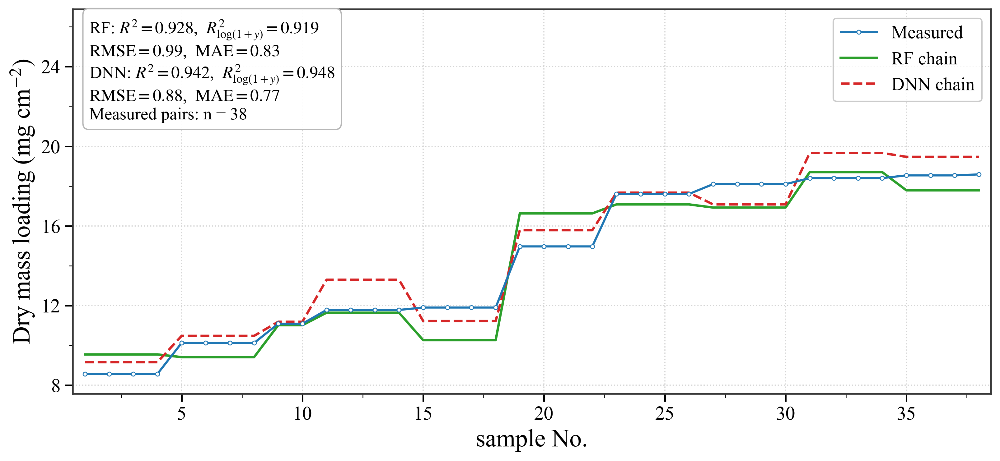

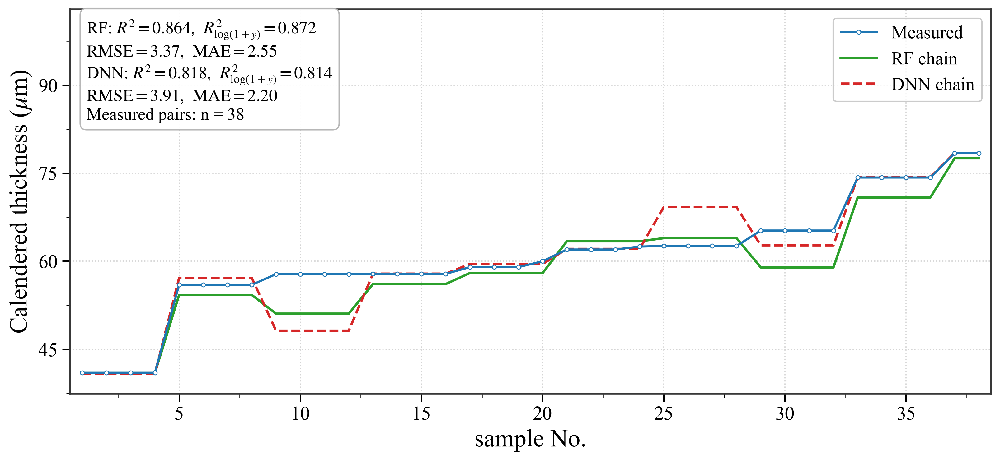

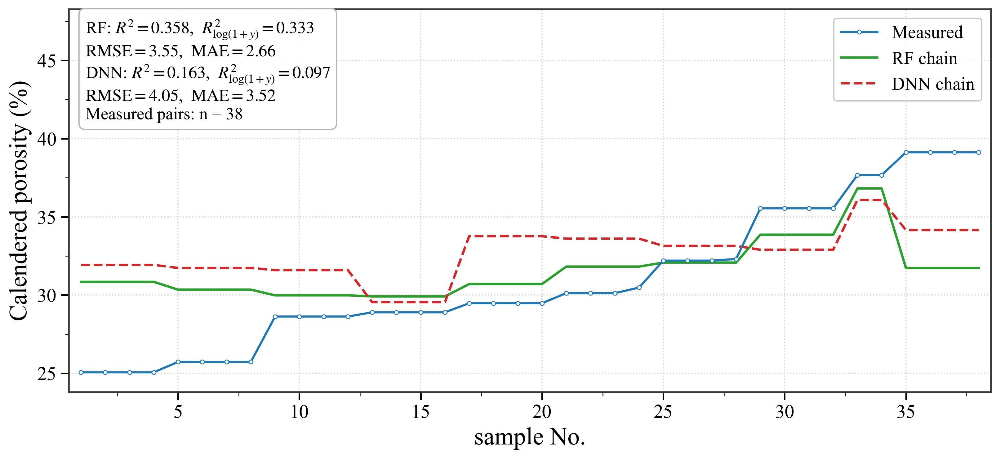

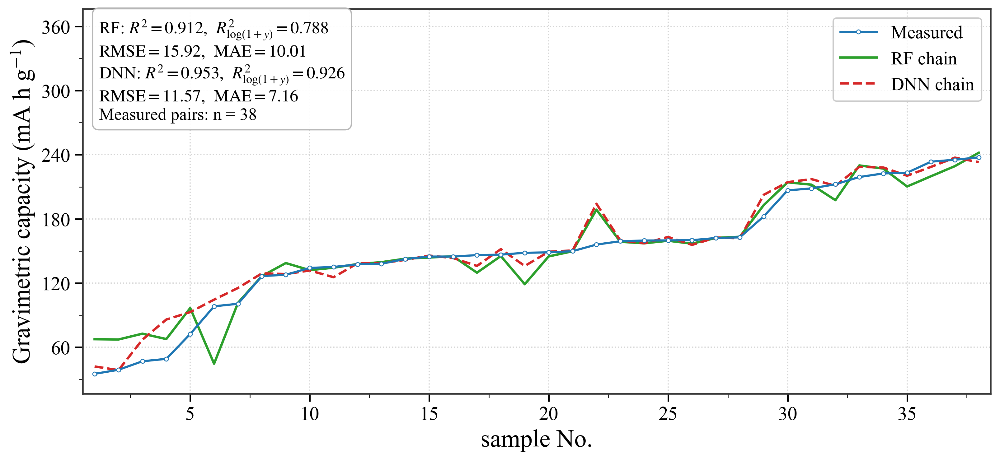

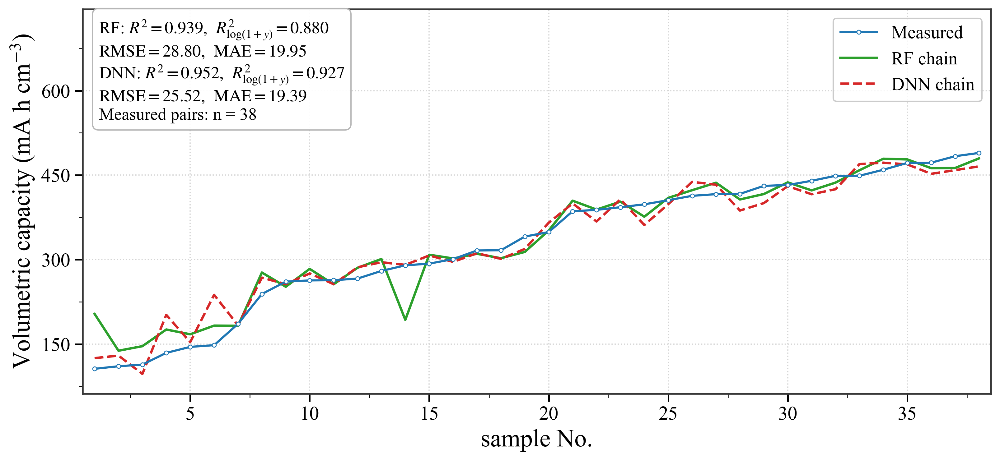

In [ ]:
VALIDATION_PLOTS = MEASURED_OUTPUTS   # choose outputs to plot
comparison = pd.concat([
    validation_metrics(pred, df_input, family)
    for family, pred in predictions.items()
], ignore_index=True)
export_table(comparison, "validation/comparison.csv")
display(comparison)
for family, pred in predictions.items():
    # Predictions are saved once under simulation/{family}/predictions.csv.
    export_table(comparison.loc[comparison.chain == family], f"validation/{family}/metrics.csv")
    if SAVE_RESULTS:
        validation_plots(pred, df_input, VALIDATION_PLOTS, family)
if SAVE_RESULTS:
    for output in VALIDATION_PLOTS:
        if output in df_input:
            show_saved_plot(execution_line_plot(predictions, df_input, output))


### 6b. Calendered porosity from dry mass and thickness

Use the user-specified fixed density reference for **every cathode: 4.54 g/cm³**, and **every anode: 2.26 g/cm³**. There is no component weighting or binder/carbon correction. Each family supplies its own predicted dry mass and calendered thickness. This is a diagnostic comparison; the original predicted porosity remains in the downstream chain.

With total dry coating mass $m_A$ in mg/cm² and foil-excluded calendered coating thickness $L$ in µm, the calculated bulk coating density is $\rho_b=10m_A/L$ in g/cm³. Porosity is $\varepsilon=100(1-\rho_b/\rho_{\mathrm{ref}})$, where $\rho_{\mathrm{ref}}$ is the fixed cathode/anode value above. The factor 10 converts units. In this equation, the supplied fixed value is the solid-density reference; bulk coating density is calculated from mass/thickness. See the density/porosity relation in [the NMC622 calendering study](https://www.mdpi.com/2313-0105/7/4/70).

Edit `ELECTRODE_DENSITIES` or foil subtraction below. Unknown electrode types raise an error. Invalid geometry yields missing values; out-of-range porosity remains visible and is flagged without clipping. “Measured” is the supplied dataset column and may itself have been calculated during dataset preparation. Solid family lines show model porosity; dashed family lines show calculated porosity.

Results are saved in `codex_work/results/<RUN_LABEL>/porosity/`. The same density assumption is used for every row of both dataset runs and in inverse-path diagnostics.


,Measured porosity (%),RF model (%),RF calculated (%),DNN model (%),DNN calculated (%)
0,32.203532,32.078408,35.019188,33.143642,30.250838
1,30.123232,31.821780,32.433811,33.606240,27.966777
2,39.125619,31.731923,28.342617,34.154658,35.405940
3,25.068215,30.847609,34.871231,31.928772,33.040298
4,25.728310,30.347212,35.913738,31.732998,33.175031


,series,n,r2,mae_percentage_points
0,RF model (%),38,0.358110,2.658895
1,RF calculated (%),38,-0.924222,4.697401
2,DNN model (%),38,0.162512,3.524928
3,DNN calculated (%),38,-0.305788,4.309856


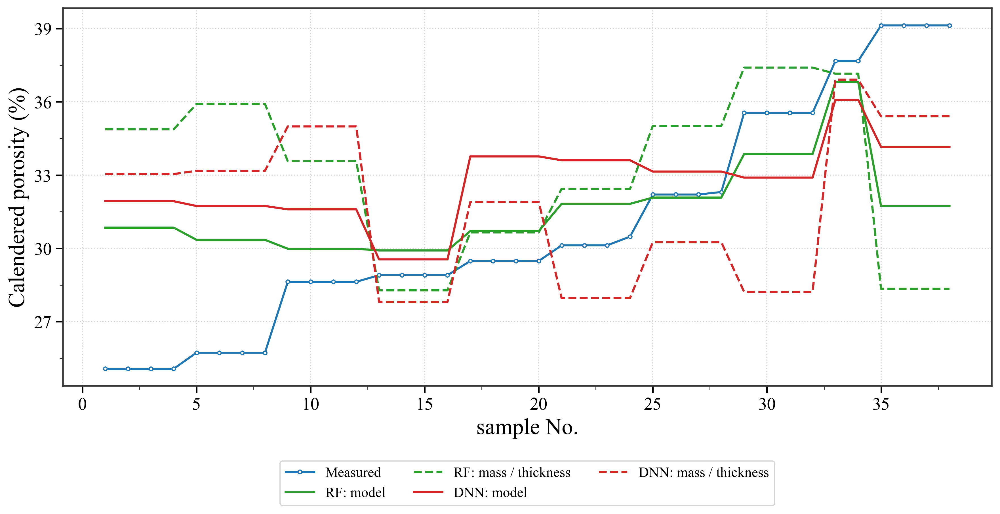

In [ ]:
# User-specified fixed solid-density references; no component mixture calculation.
ELECTRODE_DENSITIES = {"Cathode": 4.54, "Anode": 2.26}  # g/cm³
FOIL_THICKNESS_UM = 0.0   # coating-only thickness: zero; otherwise subtract foil
CALCULATED_POROSITY = "Calculated calendered porosity (%)"

def geometry_porosity(frame):
    """Use total dry coating mass, coating thickness, and the electrode-type reference."""
    names = frame["Electrode type"].astype(str).str.strip().str.lower()
    mapping = {k.lower(): v for k, v in ELECTRODE_DENSITIES.items()}
    solid_density = names.map(mapping)
    if solid_density.isna().any():
        raise ValueError(f"Missing electrode density for {names[solid_density.isna()].unique().tolist()}")
    if not np.isfinite(solid_density).all() or solid_density.le(0).any():
        raise ValueError("Electrode density references must be finite and positive.")
    mass = pd.to_numeric(frame[MASS], errors="coerce")
    thickness = pd.to_numeric(frame[CAL_THICKNESS], errors="coerce") - FOIL_THICKNESS_UM
    valid = np.isfinite(mass) & np.isfinite(thickness) & mass.gt(0) & thickness.gt(0)
    bulk = (10.0 * mass / thickness).where(valid)
    value = 100.0 * (1.0 - bulk / solid_density)
    return pd.DataFrame({"Solid density reference (g/cm3)": solid_density,
                         "Bulk coating density (g/cm3)": bulk,
                         CALCULATED_POROSITY: value,
                         "Geometry inputs valid": valid,
                         "Calculated porosity in range": valid & value.between(0, 100)}, index=frame.index)

porosity_diagnostics, porosity_comparison = {}, pd.DataFrame(index=df_input.index)
porosity_comparison["Measured porosity (%)"] = df_input[CAL_POROSITY]
for family, frame in predictions.items():
    porosity_diagnostics[family] = geometry_porosity(frame)
    porosity_comparison[f"{family} model (%)"] = frame[CAL_POROSITY]
    porosity_comparison[f"{family} calculated (%)"] = porosity_diagnostics[family][CALCULATED_POROSITY]
    export_table(porosity_diagnostics[family], f"porosity/{family}/diagnostics.csv")
export_table(porosity_comparison, "porosity/comparison.csv")
display(porosity_comparison.head())
porosity_metrics = []
for label in porosity_comparison.columns[1:]:
    actual = porosity_comparison.iloc[:, 0].to_numpy(float)
    predicted = porosity_comparison[label].to_numpy(float)
    mask = np.isfinite(actual) & np.isfinite(predicted)
    porosity_metrics.append({"series": label, "n": int(mask.sum()),
        "r2": r2_score(actual[mask], predicted[mask]) if mask.sum() >= 2 else np.nan,
        "mae_percentage_points": np.abs(predicted[mask] - actual[mask]).mean() if mask.any() else np.nan})
porosity_metrics = pd.DataFrame(porosity_metrics)
display(porosity_metrics)
export_table(porosity_metrics, "porosity/metrics.csv")
if SAVE_RESULTS:
    plt = _pyplot()
    fig, ax = plt.subplots(figsize=(12, 6.4))
    order = np.argsort(porosity_comparison.iloc[:, 0].to_numpy(float), kind="stable")
    plotted_porosity = porosity_comparison.iloc[order].copy()
    x = np.arange(1, len(df_input)+1)
    plot_data = plotted_porosity.copy()
    plot_data.insert(0, "Original row", order+1)
    plot_data.insert(0, "sample No.", x)
    export_table(plot_data, "porosity/comparison_plot_data.csv")
    ax.plot(x, plotted_porosity.iloc[:, 0], color=CHART_COLORS["Measured"],
            lw=1.7, marker="o", ms=3, markerfacecolor="white", label="Measured")
    for family in predictions:
        ax.plot(x, plotted_porosity[f"{family} model (%)"], color=CHART_COLORS[family],
                lw=1.8, ls="-", label=f"{family}: model")
        ax.plot(x, plotted_porosity[f"{family} calculated (%)"], color=CHART_COLORS[family],
                lw=1.8, ls="--", label=f"{family}: mass / thickness")
    ax.set(xlabel="sample No.", ylabel="Calendered porosity (%)")
    style_axes(ax)
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.18), ncol=3, fontsize=12)
    fig.tight_layout()
    show_saved_plot(save_figure(fig, "porosity/comparison.png"))
    plt.close(fig)


## 7. Feedback scenario: rejection of a calender-roll gap offset

**Hypothesis:** the original delayed coating-gap feedback can compensate
a small downstream roll-gap offset and restore final electrode thickness.
The default uses one held-out NMC622/PVDF/NMP recipe, repeated for 80 items.
At item 26, actual calender-roll gap increases persistently by 2 µm.
Both chains use the same 62 µm target, illustrative ±0.5 µm tolerance,
zero initial memory, and gain −1. The unchanged update is
`zeta_next = zeta_used + gain * (KPI_current - KPI_target)`.

**Matched baseline:** both branches have identical nominal histories.
After the disturbance, the baseline holds the correction already scheduled
for item 26; the active branch continues updating it. Their response at
item 26 is identical. Differences thereafter measure disturbance recovery.

Track thickness/error, applied coating gap, the imposed roll-gap offset,
post-disturbance MAE and settling within tolerance. Report both capacity
outputs as secondary consequences; restoring thickness need not improve
electrochemical capacity. Composition and discharge rate stay fixed.

The original stage-local actuator semantics are preserved. Domain and
physical checks flag violations without clipping the controller. The pilot
checked gains −0.5 and −1 for both chains and chose the common −1 setting.
These are deterministic surrogate-model results, not plant validation;
one item is a discrete feedback cycle and has no assumed duration in seconds.

The comparison describes responses induced by the two surrogate chains under the same controller, rather than ranking controllers on one real plant. The coating-gap correction remains local to Coating/Drying; downstream models receive the retained base descriptors and updated predicted intermediates. Capacity traces should be interpreted under these existing adapter semantics.


In [ ]:
import numpy as np

import pandas as pd

def run_feedback(line, frame, *, kpi_key, kpi_target, gain,
                 stage="CoatingDrying", memory_key="delta_coating_gap", initial_memory=0.0):
    if stage not in FEEDBACK_INPUTS or memory_key not in FEEDBACK_INPUTS[stage]:
        raise ValueError(f"No feedback actuator {stage}.{memory_key}")
    if not np.isfinite([kpi_target, gain, initial_memory]).all():
        raise ValueError("Feedback target, gain and initial memory must be finite")
    if kpi_key not in [c for s in line.chain_def for c in s["output_columns"]]:
        raise ValueError(f"Unknown chain-output KPI: {kpi_key}")
    results, history = simulate_with_trace(
        line, frame, use_feedback=True,
        zeta_init={stage: {memory_key: initial_memory}},
        kpi_key=kpi_key, kpi_target=kpi_target,
        feedback_gains={stage: {memory_key: gain}}, feedback_stage_name=stage,
    )
    trace = pd.DataFrame([{
        "item_index": r["item_index"], "kpi_value": r["kpi_value"],
        "kpi_target": r["kpi_target"], "error": r["error"],
        "memory_used": r["zeta_used"][stage][memory_key],
        "memory_next": r["zeta_next"][stage][memory_key],
        "adjusted_coating_gap": float(frame.iloc[i]["Coating Gap (micron)"])
                                + r["zeta_used"][stage][memory_key],
    } for i, r in enumerate(history)], index=frame.index)
    return results, trace, history


def simulate_fixed_feedback_memory(line, frame, memory):
    """Same stage maps and feature writes, with memory held fixed for all items."""
    features = chain_inputs(line, frame)
    for stage in line.chain_def:
        output = stage["func"].predict_frame(features, memory.get(stage["name"], {}))
        for column in output:
            features[column] = output[column]
    return features

def disturbance_feedback_plot(trace, family, kpi, disturbance_start, tolerance):
    plt = _pyplot()
    color = "#2ca02c" if family == "RF" else "#d62728"
    fig, axes = plt.subplots(4, 1, figsize=(11, 11), sharex=True)
    x = trace.item_index
    axes[0].plot(x, trace.kpi_value, color=color, lw=2, label="Feedback active")
    axes[0].plot(x, trace.held_kpi, color="0.4", lw=1.8, ls="--", label="Correction held after disturbance")
    target = float(trace.kpi_target.iloc[0])
    axes[0].axhline(target, color="0.15", lw=1.2, ls=":", label="Shared target")
    axes[0].axhspan(target-tolerance, target+tolerance, color="#1b7837", alpha=.10,
                   label=f"Example tolerance: ±{tolerance:g}")
    axes[0].set_ylabel(figure_label(kpi), fontsize=16)
    axes[0].legend(loc="lower right", fontsize=11, ncol=2)
    axes[1].plot(x, trace.error, color=color, lw=2)
    axes[1].plot(x, trace.held_kpi-trace.kpi_target, color="0.4", lw=1.8, ls="--")
    axes[1].axhspan(-tolerance, tolerance, color="#1b7837", alpha=.10)
    axes[1].axhline(0, color="0.2", lw=1, ls=":")
    axes[1].set_ylabel(r"Thickness error ($\mu$m)", fontsize=16)
    axes[2].plot(x, trace.adjusted_coating_gap, color=color, lw=2)
    axes[2].plot(x, trace.held_coating_gap, color="0.4", lw=1.8, ls="--")
    axes[2].set_ylabel(r"Applied coating gap ($\mu$m)", fontsize=16)
    axes[3].step(x, trace.calendering_gap, where="post", color="0.2", lw=1.8)
    axes[3].set(xlabel="sample No.", ylabel=r"Calender-roll gap ($\mu$m)")
    axes[3].yaxis.label.set_size(16)
    for i, ax in enumerate(axes):
        style_axes(ax)
        ax.axvline(disturbance_start-.5, color="0.45", lw=1.1, ls="-.")
        ax.text(.012, .97, f"({chr(97+i)})", transform=ax.transAxes, va="top", fontsize=16)
    offset = trace.calendering_gap.iloc[-1] - trace.calendering_gap.iloc[0]
    post = trace.loc[trace.item_index >= disturbance_start]
    active_mae = post.error.abs().mean()
    held_mae = (post.held_kpi - post.kpi_target).abs().mean()
    caption = (f"After offset: MAE active = {active_mae:.3f} µm; held = {held_mae:.3f} µm. "
               f"Final error = {trace.error.iloc[-1]:+.3f} µm.")
    fig.text(.5, .005, caption, ha="center", fontsize=12)
    fig.tight_layout(rect=(0, .025, 1, 1))
    path = save_figure(fig, f"feedback/scenario/{family}/disturbance_response.png")
    plt.close(fig)
    return path

def feedback_capacity_plot(controlled, held, family, disturbance_start):
    plt = _pyplot()
    fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    x = np.arange(1, len(controlled)+1)
    color = "#2ca02c" if family == "RF" else "#d62728"
    for i, (ax, output) in enumerate(zip(axes, [GRAVIMETRIC, VOLUMETRIC])):
        ax.plot(x, controlled[output], color=color, lw=2, label="Feedback active")
        ax.plot(x, held[output], color="0.4", lw=1.8, ls="--", label="Correction held")
        ax.axvline(disturbance_start-.5, color="0.45", lw=1.1, ls="-.")
        ax.set_ylabel(figure_label(output), fontsize=16)
        style_axes(ax)
        ax.text(.015, .97, f"({chr(97+i)})", transform=ax.transAxes, va="top")
    axes[0].legend(loc="best", fontsize=12)
    axes[1].set_xlabel("sample No.")
    fig.tight_layout()
    path = save_figure(fig, f"feedback/scenario/{family}/capacity_consequences.png")
    plt.close(fig)
    return path


Edit the shared recipe row, specification, disturbance and gain below. Changing the material requires checking feasibility again. Exported scenario inputs, predictions, traces and summary are in `codex_work/results/<RUN_LABEL>/feedback/scenario/`.


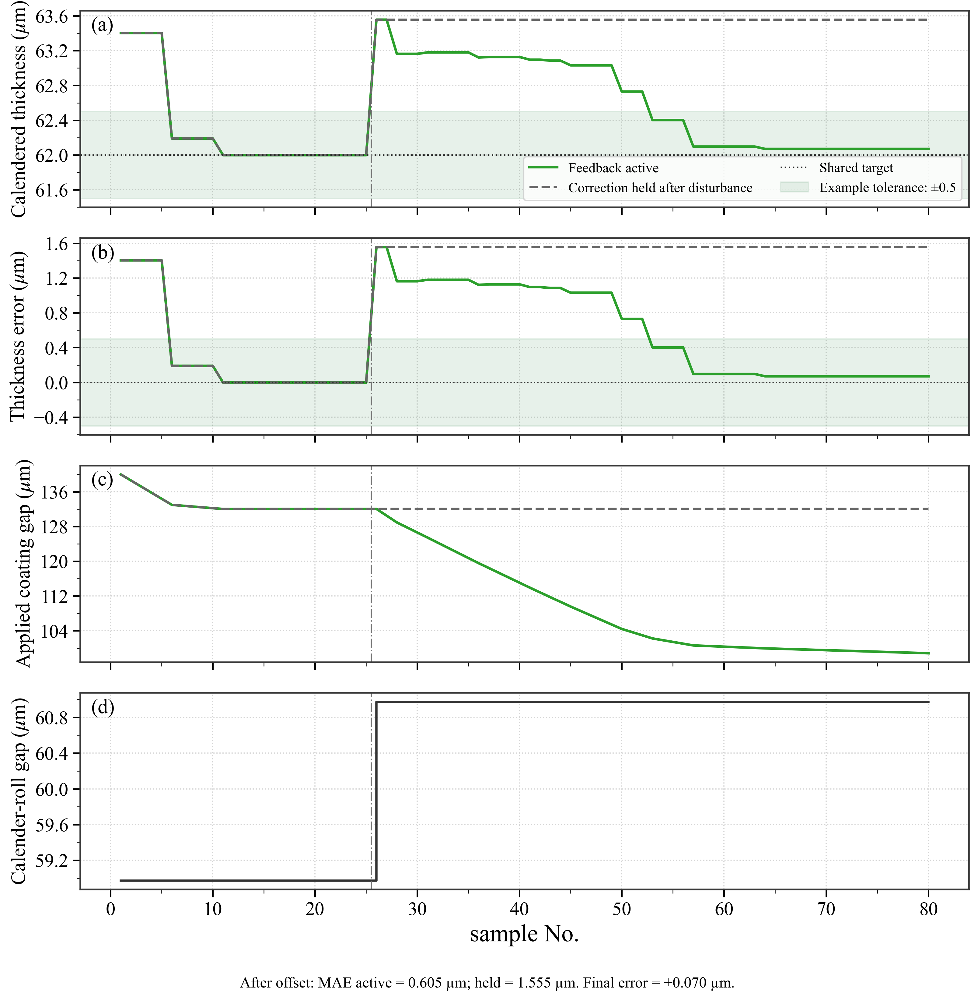

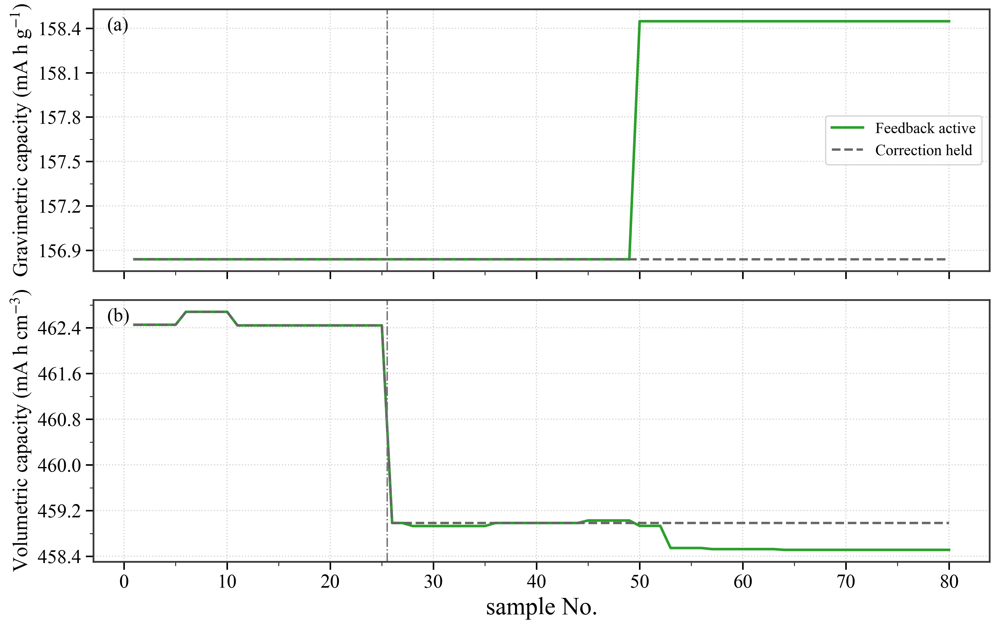

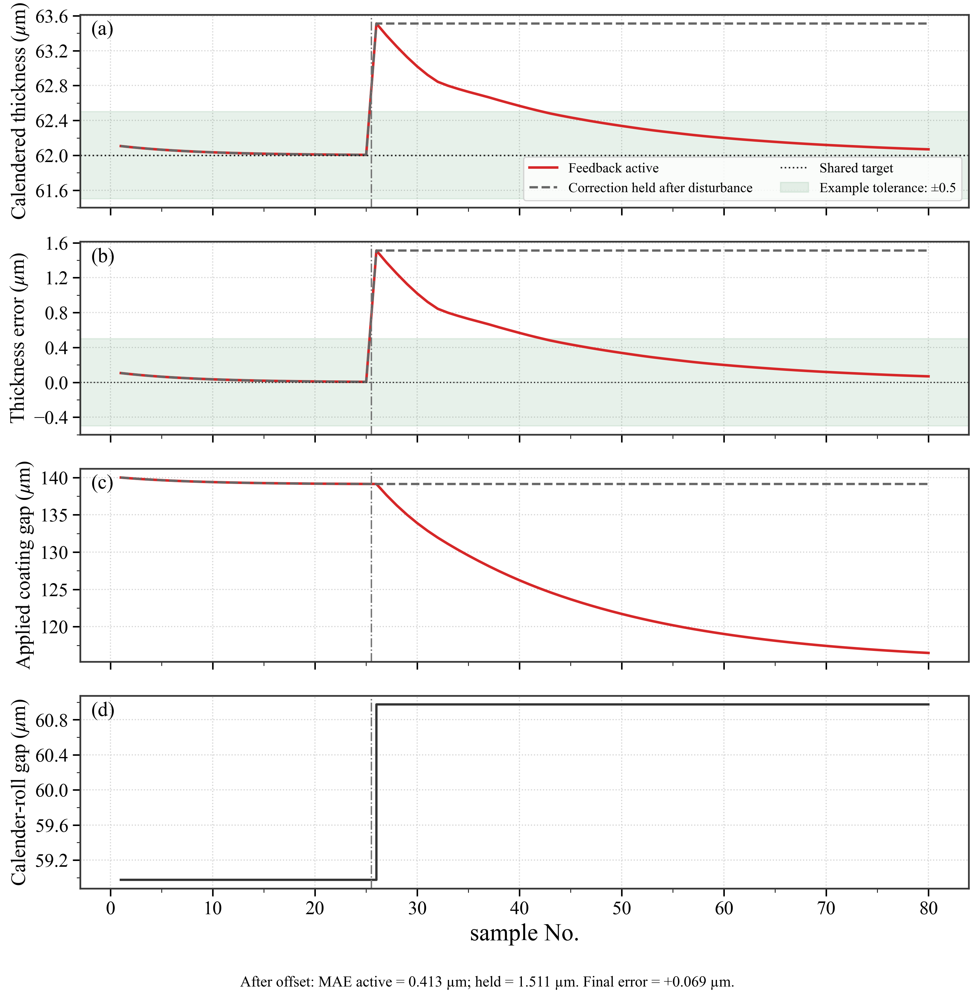

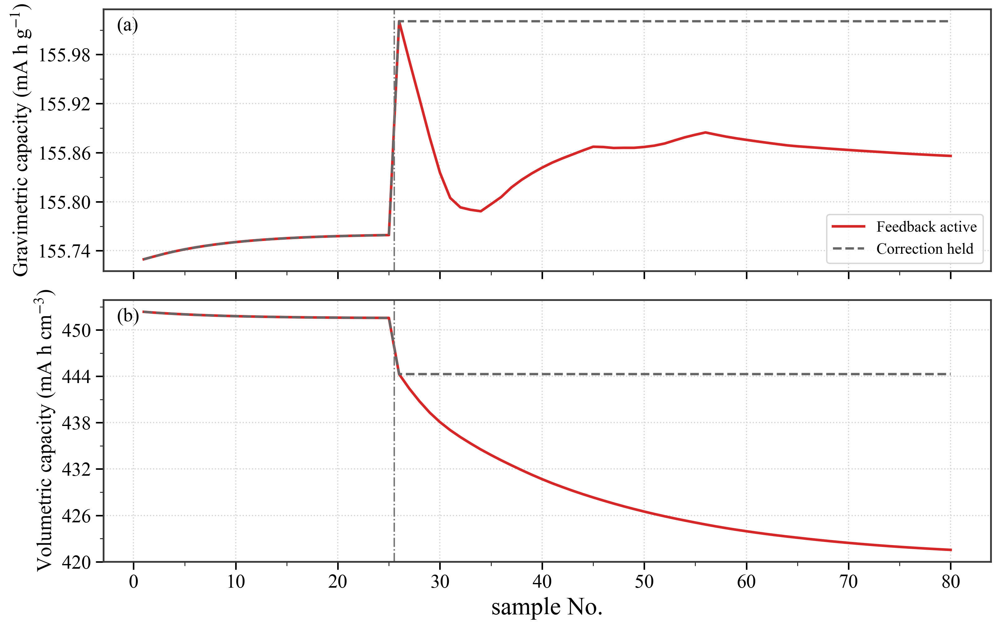

Nominal recipe: Cathode NMC622 PVDF NMP
Reference coating-gap range: (68.0, 140.0) µm (marginal bounds, not proof of joint support)


,chain,target_um,tolerance_um,gain,disturbance_item,post_disturbance_mae_active_um,post_disturbance_mae_held_um,final_error_um,settled_from_item,items_to_settle,minimum_coating_gap_um,maximum_coating_gap_um,all_gaps_within_reference_range,final_gravimetric_active,final_gravimetric_held,final_volumetric_active,final_volumetric_held
0,RF,62.0,0.5,-1.0,26,0.605473,1.555306,0.070125,53,27,98.831760,140.0,True,158.447446,156.839042,458.512485,458.982968
1,DNN,62.0,0.5,-1.0,26,0.413303,1.511245,0.068703,43,17,116.472871,140.0,True,155.855987,156.020735,421.534943,444.291525


In [ ]:
# Fixed recipe, common target and common controller parameters for both chains.
FEEDBACK_ROW = 0                     # first test row: NMC622 cathode / PVDF / NMP
FEEDBACK_KPI = CAL_THICKNESS
FEEDBACK_TARGET = 62.0               # illustrative product specification, in µm
FEEDBACK_TOLERANCE = 0.5             # illustrative tolerance, not a claimed industry standard
FEEDBACK_GAIN = -1.0                 # µm coating-gap correction per µm thickness error
FEEDBACK_INITIAL_MEMORY = 0.0
FEEDBACK_ITEMS = 80
DISTURBANCE_START = 26               # one-based execution item
DISTURBANCE_COLUMN = "Calendaring Gap (um)"
DISTURBANCE_SIZE = 2.0               # persistent +2 µm roll-gap offset
if not 1 < DISTURBANCE_START <= FEEDBACK_ITEMS:
    raise ValueError("Include a nominal phase before the disturbance.")

base = chain_inputs(rf_line, df_input).iloc[FEEDBACK_ROW].to_dict()
feedback_items = pd.DataFrame([base] * FEEDBACK_ITEMS)
step_index = DISTURBANCE_START - 1
feedback_items.loc[step_index:, DISTURBANCE_COLUMN] += DISTURBANCE_SIZE
# Discharge rate and composition stay fixed; both model families see identical inputs.
same_recipe = ((reference_data["Electrode type"] == base["Electrode type"]) &
               (reference_data["Chemistry"] == base["Chemistry"]))
gap_reference = reference_data.loc[same_recipe, "Coating Gap (micron)"]
gap_bounds = (float(gap_reference.min()), float(gap_reference.max()))
feedback_results, feedback_traces, feedback_histories, held_results = {}, {}, {}, {}
scenario_summary = []
export_table(feedback_items, "feedback/scenario/identical_input_sequence.csv")

for family, line in chains.items():
    controlled, trace, history = run_feedback(
        line, feedback_items, kpi_key=FEEDBACK_KPI, kpi_target=FEEDBACK_TARGET,
        gain=FEEDBACK_GAIN, initial_memory=FEEDBACK_INITIAL_MEMORY)
    # Matched counterfactual: identical nominal history; freeze the correction
    # that is already scheduled for the first disturbed item. No retuning.
    frozen_memory = float(trace.memory_used.iloc[step_index])
    held = controlled.copy()
    held_post = simulate_fixed_feedback_memory(
        line, feedback_items.iloc[step_index:],
        {"CoatingDrying": {"delta_coating_gap": frozen_memory}})
    held.loc[held_post.index, OUTPUT_COLUMNS] = held_post[OUTPUT_COLUMNS]
    trace["held_kpi"] = held[FEEDBACK_KPI].to_numpy()
    trace["held_coating_gap"] = trace.adjusted_coating_gap.copy()
    trace.loc[step_index:, "held_coating_gap"] = base["Coating Gap (micron)"] + frozen_memory
    trace["calendering_gap"] = feedback_items[DISTURBANCE_COLUMN].to_numpy()
    trace["within_tolerance"] = trace.error.abs() <= FEEDBACK_TOLERANCE
    trace["gap_within_reference_range"] = trace.adjusted_coating_gap.between(*gap_bounds)
    trace["calendered_thinner_than_dry"] = controlled[CAL_THICKNESS] < controlled[DRY_THICKNESS]
    trace["roll_gap_less_than_dry_thickness"] = feedback_items[DISTURBANCE_COLUMN] < controlled[DRY_THICKNESS]
    trace["calendered_porosity_in_range"] = controlled[CAL_POROSITY].between(0, 100)
    trace["positive_mass_loading"] = controlled[MASS] > 0
    # At disturbance onset, active and held branches must have the same memory and response.
    np.testing.assert_allclose(controlled.loc[step_index, OUTPUT_COLUMNS].to_numpy(float),
                               held.loc[step_index, OUTPUT_COLUMNS].to_numpy(float),
                               rtol=2e-5, atol=2e-4)
    post = trace.iloc[step_index:]
    held_error = post.held_kpi - FEEDBACK_TARGET
    settled = next((int(post.item_index.iloc[j]) for j in range(len(post))
                    if post.within_tolerance.iloc[j:].all()), None)
    scenario_summary.append({
        "chain": family, "target_um": FEEDBACK_TARGET, "tolerance_um": FEEDBACK_TOLERANCE,
        "gain": FEEDBACK_GAIN, "disturbance_item": DISTURBANCE_START,
        "post_disturbance_mae_active_um": post.error.abs().mean(),
        "post_disturbance_mae_held_um": held_error.abs().mean(),
        "final_error_um": trace.error.iloc[-1], "settled_from_item": settled,
        "items_to_settle": settled-DISTURBANCE_START if settled is not None else np.nan,
        "minimum_coating_gap_um": trace.adjusted_coating_gap.min(),
        "maximum_coating_gap_um": trace.adjusted_coating_gap.max(),
        "all_gaps_within_reference_range": bool(trace.gap_within_reference_range.all()),
        "final_gravimetric_active": controlled[GRAVIMETRIC].iloc[-1],
        "final_gravimetric_held": held[GRAVIMETRIC].iloc[-1],
        "final_volumetric_active": controlled[VOLUMETRIC].iloc[-1],
        "final_volumetric_held": held[VOLUMETRIC].iloc[-1],
    })
    feedback_results[family], feedback_traces[family], feedback_histories[family] = controlled, trace, history
    held_results[family] = held
    export_table(controlled, f"feedback/scenario/{family}/controlled_predictions.csv")
    export_table(held, f"feedback/scenario/{family}/held_predictions.csv")
    export_table(trace, f"feedback/scenario/{family}/trace.csv")
    if SAVE_RESULTS:
        show_saved_plot(disturbance_feedback_plot(trace, family, FEEDBACK_KPI,
                                                  DISTURBANCE_START, FEEDBACK_TOLERANCE))
        show_saved_plot(feedback_capacity_plot(controlled, held, family, DISTURBANCE_START))
scenario_summary = pd.DataFrame(scenario_summary)
export_table(scenario_summary, "feedback/scenario/summary.csv")
print("Nominal recipe:", base["Electrode type"], base["Chemistry"], base["Binder1 type"], base["Solvent"])
print("Reference coating-gap range:", gap_bounds, "µm (marginal bounds, not proof of joint support)")
display(scenario_summary)


## 8. Parametric simulation

Change the base row and the candidate ranges below. The same candidates are
evaluated independently by both chains. The Cartesian sweep keeps all rows;
physical checks are flags and do not modify predictions.

Optional `USE_ORIGINAL_ANODE_RECIPE` retains the original shear-rate,
94/1/3/2 composition and slurry-density formulas for GRA/SBR/CMC/water anodes.
With the default `False`, named inputs are varied independently.


In [ ]:
from itertools import product

import numpy as np

import pandas as pd

def parametric_inputs(base_row, ranges, *, derived=None, max_items=100_000):
    if not ranges or any(len(values) == 0 for values in ranges.values()):
        raise ValueError("Supply at least one nonempty parameter range")
    count = int(np.prod([len(v) for v in ranges.values()], dtype=object))
    if count > max_items:
        raise ValueError(f"Sweep has {count} items; max_items={max_items}")
    records = []
    for values in product(*ranges.values()):
        row = dict(base_row)
        row.update(zip(ranges, values))
        if derived is not None:
            row = derived(row)
        records.append(row)
    return pd.DataFrame(records)

def original_anode_recipe(row):
    """Original parametric notebook's shear, composition and density formulas.

    Explicitly opt in only for the GRA/SBR/CMC/water recipe used in that notebook.
    Does not run inside orchestration or importance calculations.
    """
    row = dict(row)
    if (row["Electrode type"], row["Chemistry"], row["Binder1 type"],
        row["Binder2 (Thickener) type"], row["Solvent"]) != ("Anode", "GRA", "SBR", "CMC", "water"):
        raise ValueError("Original parametric recipe is for GRA/SBR/CMC/water anodes")
    sc = float(row["Solid Content (%)"])
    gap = float(row["Coating Gap (micron)"])
    if gap <= 0:
        raise ValueError("Coating gap must be positive")
    row["Shear rate"] = (float(row["Coating Speed (m/min)"]) / 60) / (gap / 1e6)
    row["Am/total weight%"] = 0.94 * sc
    row["Conductive additive/total weight %"] = 0.01 * sc
    row["Binder1/total weight %"] = 0.03 * sc
    row["Binder2 (thickener)/total weight %"] = 0.02 * sc
    row["Slurry density g/cm3"] = (
        row["Am/total weight%"] * 2.26 / 100
        + row["Conductive additive/total weight %"] * 1.6 / 100
        + row["Binder1/total weight %"] * 1.3 / 100
        + row["Binder2 (thickener)/total weight %"] * 1.6 / 100
        + (100 - sc * 1) / 100
    )
    return row

def run_parametric(line, inputs, batch_size=2048):
    if batch_size < 1:
        raise ValueError("batch_size must be positive")
    parts = [simulate_without_feedback(line, inputs.iloc[i:i + batch_size])
             for i in range(0, len(inputs), batch_size)]
    return pd.concat(parts) if parts else simulate_without_feedback(line, inputs)

def physical_checks(results):
    """Flag observed physical violations; never delete rows or alter model outputs.

    Wet-coating thickness no longer exists. Dried porosity's units are not encoded
    in its saved target name, so avoid a guessed percentage/fraction upper bound.
    """
    checks = pd.DataFrame(index=results.index)
    for name in [MASS, DRY_THICKNESS, CAL_THICKNESS]:
        checks[f"{name}: positive"] = results[name].gt(0) & np.isfinite(results[name])
    checks["calendered_thinner_than_dry"] = results[CAL_THICKNESS] < results[DRY_THICKNESS]
    checks["roll_gap_less_than_dry_thickness"] = results["Calendaring Gap (um)"] < results[DRY_THICKNESS]
    checks["calendered_porosity_in_percent_range"] = results[CAL_POROSITY].between(0, 100)
    checks["dry_porosity_nonnegative_finite"] = results[DRY_POROSITY].ge(0) & np.isfinite(results[DRY_POROSITY])
    checks["all_checks"] = checks.all(axis=1)
    return checks

def numeric_correlations(results, method="pearson", drop_columns=()):
    if method not in {"pearson", "spearman"}:
        raise ValueError("Correlation method must be pearson or spearman")
    data = results.drop(columns=list(drop_columns), errors="ignore").select_dtypes("number")
    data = data.loc[:, data.nunique(dropna=False) > 1].dropna()
    return data.corr(method=method)

def filter_tolerances(results, bounds):
    mask = pd.Series(True, index=results.index)
    for column, (lower, upper) in bounds.items():
        if lower > upper:
            raise ValueError(f"Invalid tolerance for {column}")
        mask &= results[column].between(lower, upper)
    return results.loc[mask].copy()


The default sweep contains 108 candidate items. Set your own ranges or replace `candidate_inputs` with a DataFrame.


In [ ]:
SWEEP_BASE_ROW = 0
SWEEP_RANGES = {
    "Coating Gap (micron)": [100, 120, 140, 160],
    "Drying temp-Zone2": [85, 100, 110],
    "Calendaring Gap (um)": [45, 55, 65],
    "Discharge rate (*C)": [0.2, 1.0, 2.0],
}
USE_ORIGINAL_ANODE_RECIPE = False
base_row = chain_inputs(rf_line, df_input).iloc[SWEEP_BASE_ROW].to_dict()
candidate_inputs = parametric_inputs(
    base_row, SWEEP_RANGES,
    derived=original_anode_recipe if USE_ORIGINAL_ANODE_RECIPE else None)
sweep_results, sweep_flags = {}, {}
for family, line in chains.items():
    sweep_results[family] = run_parametric(line, candidate_inputs)
    sweep_flags[family] = physical_checks(sweep_results[family])
    export_table(sweep_results[family], f"parametric/{family}/predictions.csv")
    export_table(sweep_flags[family], f"parametric/{family}/physical_checks.csv")
    print(family, "all physical checks:", int(sweep_flags[family].all_checks.sum()),
          "of", len(candidate_inputs))
    display(sweep_results[family][OUTPUT_COLUMNS].head())


RF all physical checks: 108 of 108


,Viscosity (Pa.s),Mass loading dry (mg/cm2),Dry Coating Thickness (µm),Dried Porosity,Calendered thickness (um),Calendered porosity (%),Gravimetric capacity (mA h/g),Volumetric capacity (mA h/cm3)
0,1.215207,14.125014,78.603749,49.076628,52.712597,34.333271,170.740832,439.979358
1,1.215207,14.125014,78.603749,49.076628,52.712597,34.333271,156.982374,396.780734
2,1.215207,14.125014,78.603749,49.076628,52.712597,34.333271,145.698296,375.402187
3,1.215207,14.125014,78.603749,49.076628,55.251698,33.114465,169.185286,451.357078
4,1.215207,14.125014,78.603749,49.076628,55.251698,33.114465,156.505195,411.815180


DNN all physical checks: 105 of 108


,Viscosity (Pa.s),Mass loading dry (mg/cm2),Dry Coating Thickness (µm),Dried Porosity,Calendered thickness (um),Calendered porosity (%),Gravimetric capacity (mA h/g),Volumetric capacity (mA h/cm3)
0,1.72909,13.504999,79.921735,48.034706,47.921708,31.479531,157.414875,453.124419
1,1.72909,13.504999,79.921735,48.034706,47.921708,31.479531,145.969384,420.890377
2,1.72909,13.504999,79.921735,48.034706,47.921708,31.479531,136.977493,391.496483
3,1.72909,13.504999,79.921735,48.034706,55.280085,33.268101,156.234979,430.684475
4,1.72909,13.504999,79.921735,48.034706,55.280085,33.268101,144.558518,397.631750


## 9. Correlations, scatter views, parallel coordinates and tolerance selections

Pearson/Spearman correlations describe the candidate sweep and its chosen
ranges. They are separate from feature importance. Constant numeric columns
are omitted. Select scatter axes and color below.


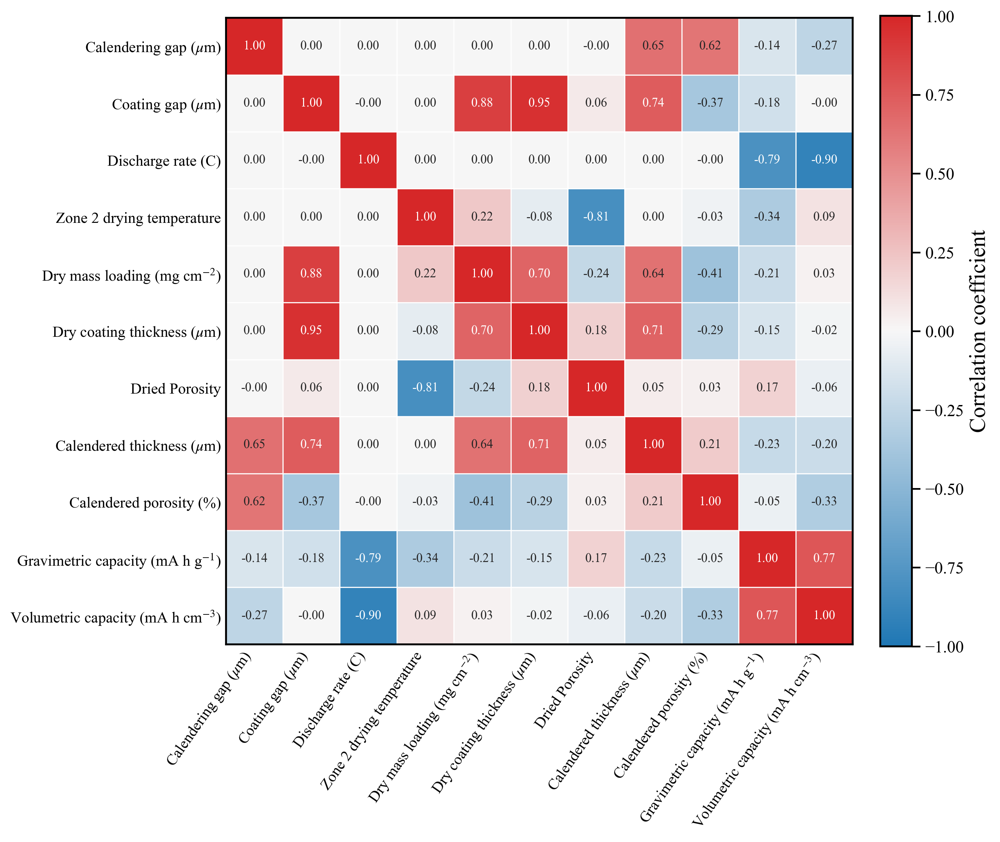

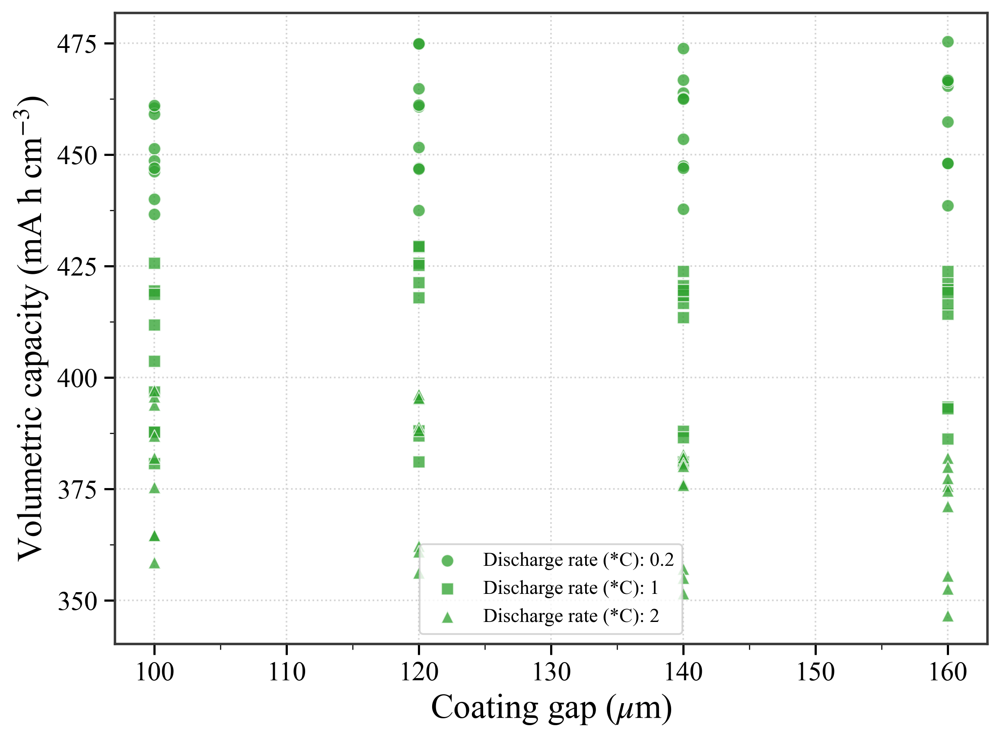

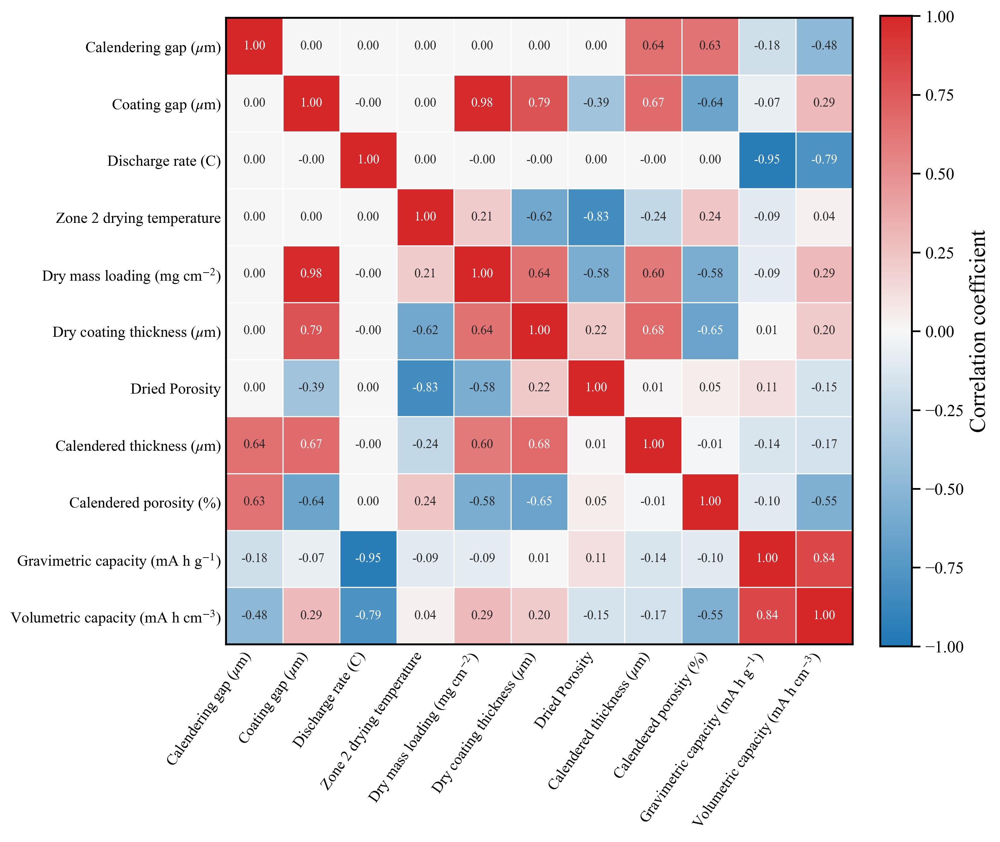

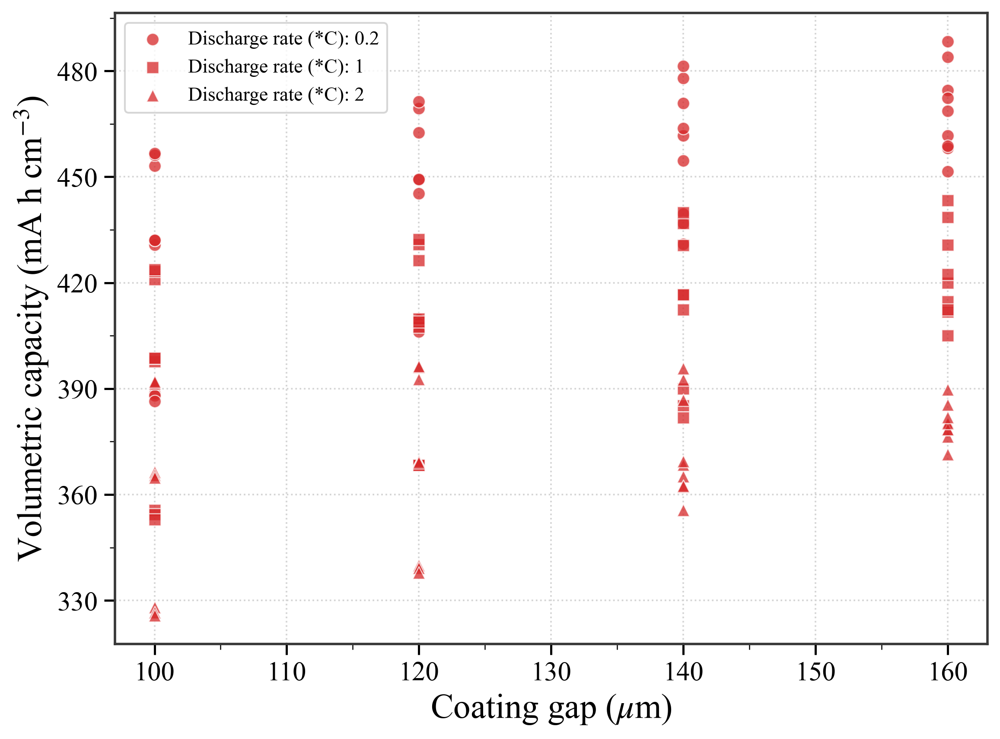

In [ ]:
SCATTER_X = "Coating Gap (micron)"
SCATTER_Y = VOLUMETRIC
SCATTER_GROUP = "Discharge rate (*C)"
CORRELATION_METHODS = ["pearson", "spearman"]
plt = _pyplot()
for family, results in sweep_results.items():
    for method in CORRELATION_METHODS:
        correlation = numeric_correlations(results, method)
        export_table(correlation, f"parametric/{family}/{method}.csv", index=True)
        if SAVE_RESULTS and method == "pearson":
            show_saved_plot(correlation_plot(correlation, family, method))
        elif SAVE_RESULTS:
            correlation_plot(correlation, family, method)
    fig, ax = plt.subplots(figsize=(8, 6))
    markers = ["o", "s", "^", "D", "v", "P", "X"]
    for i, (level, group) in enumerate(results.groupby(SCATTER_GROUP, sort=True)):
        ax.scatter(group[SCATTER_X], group[SCATTER_Y], color=CHART_COLORS[family],
                   marker=markers[i % len(markers)], s=48, alpha=.75,
                   edgecolors="white", linewidths=.6, label=f"{SCATTER_GROUP}: {level:g}")
    ax.set(xlabel=figure_label(SCATTER_X), ylabel=figure_label(SCATTER_Y))
    style_axes(ax)
    ax.legend(fontsize=11)
    fig.tight_layout()
    if SAVE_RESULTS:
        show_saved_plot(save_figure(fig, f"parametric/{family}/scatter.png"))
    plt.close(fig)


Parallel-coordinate views are saved as self-contained local HTML files.
Edit the displayed dimensions and the tolerance bounds below. Tolerance groups
select rows without altering predictions. Later groups take precedence if
bounds overlap. These bounds are editable example selections.


In [ ]:
PARALLEL_COLUMNS = list(SWEEP_RANGES) + OUTPUT_COLUMNS
PARALLEL_COLOR = GRAVIMETRIC
TOLERANCE_GROUPS = {
    "A": {GRAVIMETRIC: (150, 170), CAL_POROSITY: (30, 37), CAL_THICKNESS: (60, 70)},
    "B": {GRAVIMETRIC: (100, 150), CAL_POROSITY: (28, 32), CAL_THICKNESS: (50, 65)},
    "C": {VOLUMETRIC: (400, 500), CAL_POROSITY: (30, 37), CAL_THICKNESS: (62, 65)},
}
tolerance_results = {}
for family, results in sweep_results.items():
    tolerance_results[family] = {}
    grouped = results.copy()
    grouped["tolerance_group"] = 0
    for group_number, (name, bounds) in enumerate(TOLERANCE_GROUPS.items(), start=1):
        selected = filter_tolerances(results, bounds)
        tolerance_results[family][name] = selected
        grouped.loc[selected.index, "tolerance_group"] = group_number
        export_table(selected, f"parametric/{family}/tolerance_{name}.csv")
        print(family, name, "selected:", len(selected))
    if SAVE_RESULTS:
        for path in [
            parallel_coordinates(results, PARALLEL_COLUMNS, PARALLEL_COLOR, family),
            parallel_coordinates(grouped, PARALLEL_COLUMNS, "tolerance_group", family,
                                 name="parallel_coordinates_tolerance_groups")
        ]:
            display(FileLink(str(path.relative_to(ROOT))))


RF A selected: 21
RF B selected: 21
RF C selected: 12


C:\Users\Tavako_M\OneDrive - University of Warwick\Workstation\BATTWIN Project\Paper1-Formal framework\New_upstream_models\Framework-level\codex_work\results\test_aggregated_deterministic\parametric\RF\parallel_coordinates.html

C:\Users\Tavako_M\OneDrive - University of Warwick\Workstation\BATTWIN Project\Paper1-Formal framework\New_upstream_models\Framework-level\codex_work\results\test_aggregated_deterministic\parametric\RF\parallel_coordinates_tolerance_groups.html

DNN A selected: 9
DNN B selected: 16
DNN C selected: 0


C:\Users\Tavako_M\OneDrive - University of Warwick\Workstation\BATTWIN Project\Paper1-Formal framework\New_upstream_models\Framework-level\codex_work\results\test_aggregated_deterministic\parametric\DNN\parallel_coordinates.html

C:\Users\Tavako_M\OneDrive - University of Warwick\Workstation\BATTWIN Project\Paper1-Formal framework\New_upstream_models\Framework-level\codex_work\results\test_aggregated_deterministic\parametric\DNN\parallel_coordinates_tolerance_groups.html

## 10. RF whole-chain permutation feature importance

PFI permutes one original input at a time, recomputes all stages and compares
with fixed measured targets. For R², importance = baseline score − permuted
score. For RMSE, importance = permuted RMSE − baseline RMSE. Negative values
are retained. Numeric and categorical base inputs can both be permuted.
Feedback is off. Each permuted run evaluates every selected target together.


In [ ]:
from sklearn.metrics import r2_score, mean_squared_error

def rf_chain_pfi(line, frame, truth, features, outputs, repeats=12, seed=42, metric="r2"):
    if line.family != "RF":
        raise ValueError("PFI belongs to the RF-labelled tree chain.")
    if metric not in {"r2", "rmse"} or repeats < 1:
        raise ValueError("Choose r2/rmse and at least one repeat.")
    inputs = chain_inputs(line, frame)
    if len(inputs) != len(truth) or not inputs.index.equals(truth.index):
        raise ValueError("PFI inputs and measured targets must have matching row indices.")
    if set(features) - set(inputs.columns) or set(outputs) - set(OUTPUT_COLUMNS):
        raise ValueError("Select base input features and actual chain outputs.")
    true = {}
    masks = {}
    for output in outputs:
        if output not in truth:
            raise KeyError(f"No measured target for PFI: {output}")
        true[output] = pd.to_numeric(truth[output], errors="coerce").to_numpy(float)
        masks[output] = np.isfinite(true[output])
        if masks[output].sum() < 2:
            raise ValueError(f"PFI requires at least two measured values: {output}")

    def scores(prediction):
        values = {}
        for output in outputs:
            mask = masks[output]
            y, pred = true[output][mask], prediction[output].to_numpy(float)[mask]
            values[output] = (r2_score(y, pred) if metric == "r2"
                              else np.sqrt(mean_squared_error(y, pred)))
        return values

    baseline = scores(simulate_without_feedback(line, inputs))
    rng = np.random.default_rng(seed)
    records = []
    for feature in features:
        deltas = {output: [] for output in outputs}
        for _ in range(repeats):
            permuted = inputs.copy()
            permuted[feature] = rng.permutation(permuted[feature].to_numpy())
            permuted_score = scores(simulate_without_feedback(line, permuted))
            for output in outputs:
                delta = (baseline[output] - permuted_score[output] if metric == "r2"
                         else permuted_score[output] - baseline[output])
                deltas[output].append(delta)
        for output, values in deltas.items():
            records.append({"chain": "RF", "output": output, "feature": feature,
                            f"baseline_{metric}": baseline[output],
                            "mean_importance": np.mean(values),
                            "std_importance": np.std(values, ddof=1) if repeats > 1 else 0,
                            "min_importance": min(values), "max_importance": max(values),
                            "all_importances": values, "n_repeats": repeats, "random_state": seed})
    return pd.DataFrame(records).sort_values(["output", "mean_importance"], ascending=[True, False])


Edit the PFI targets, features, repeats and scoring metric here. The default includes all 25 inputs and all five measured targets.


,chain,output,feature,baseline_r2,mean_importance,std_importance,min_importance,max_importance,all_importances,n_repeats,random_state
27,RF,Calendered porosity (%),Calendaring Gap (um),0.358110,0.404805,0.185543,0.037075,0.672038,"[0.5467898206822003, 0.03707478278638898, 0.21...",12,42
47,RF,Calendered porosity (%),Coating Gap (micron),0.358110,0.344731,0.092862,0.229842,0.478070,"[0.3707683564009955, 0.33080657112327205, 0.47...",12,42
97,RF,Calendered porosity (%),Electrode type,0.358110,0.045358,0.019524,0.022841,0.087308,"[0.0438816424889682, 0.030209787935373655, 0.0...",12,42
37,RF,Calendered porosity (%),Calendering Roll speed(m/min),0.358110,0.036245,0.028876,0.005302,0.082621,"[0.005301830891550008, 0.01850390092635279, 0....",12,42
107,RF,Calendered porosity (%),Shear rate,0.358110,0.031749,0.027611,0.003508,0.080973,"[0.0042156804525155245, 0.08097344761347913, 0...",12,42
46,RF,Calendered thickness (um),Coating Gap (micron),0.864376,0.660368,0.153814,0.388942,0.857958,"[0.8389825167663062, 0.7151918978110658, 0.688...",12,42
26,RF,Calendered thickness (um),Calendaring Gap (um),0.864376,0.186438,0.044609,0.110311,0.257344,"[0.15287614975499964, 0.18456796824818222, 0.1...",12,42
106,RF,Calendered thickness (um),Shear rate,0.864376,0.060149,0.019943,0.032610,0.095198,"[0.06506971189936428, 0.032610038393623975, 0....",12,42
11,RF,Calendered thickness (um),Binder1/total weight %,0.864376,0.025403,0.007238,0.014695,0.035089,"[0.02565519718003928, 0.03508937746823593, 0.0...",12,42
1,RF,Calendered thickness (um),Am/total weight%,0.864376,0.022512,0.008165,0.007928,0.035808,"[0.011397190652358113, 0.03580810338632767, 0....",12,42


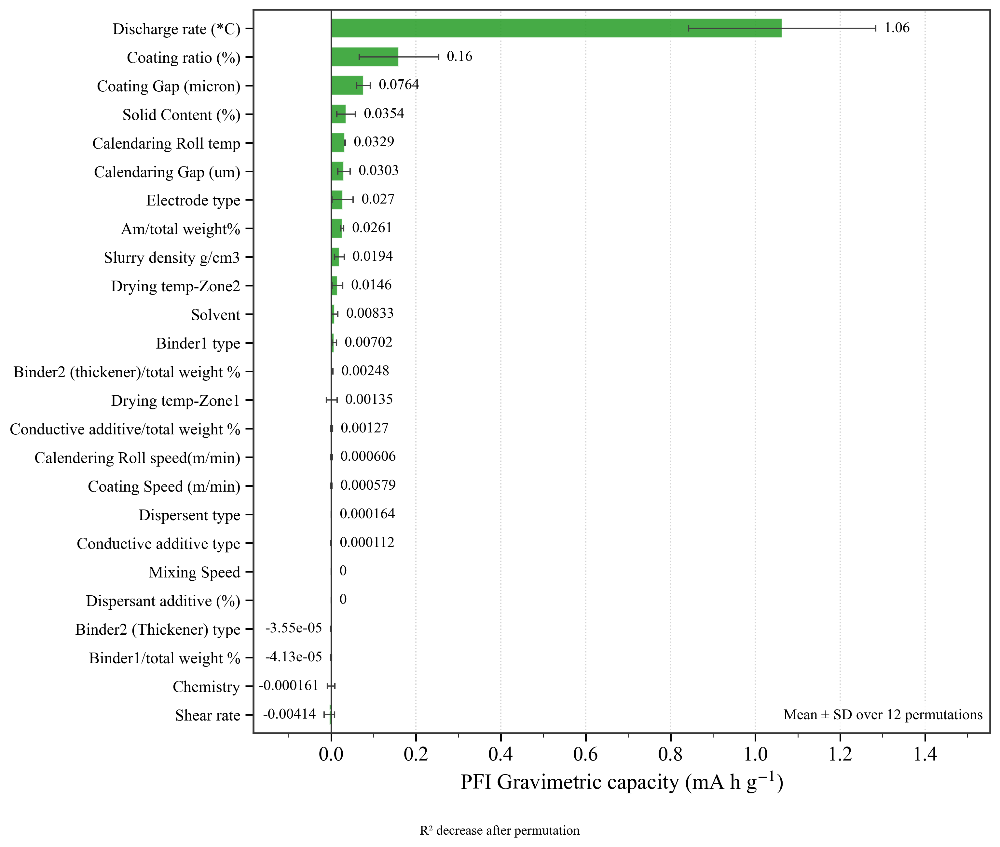

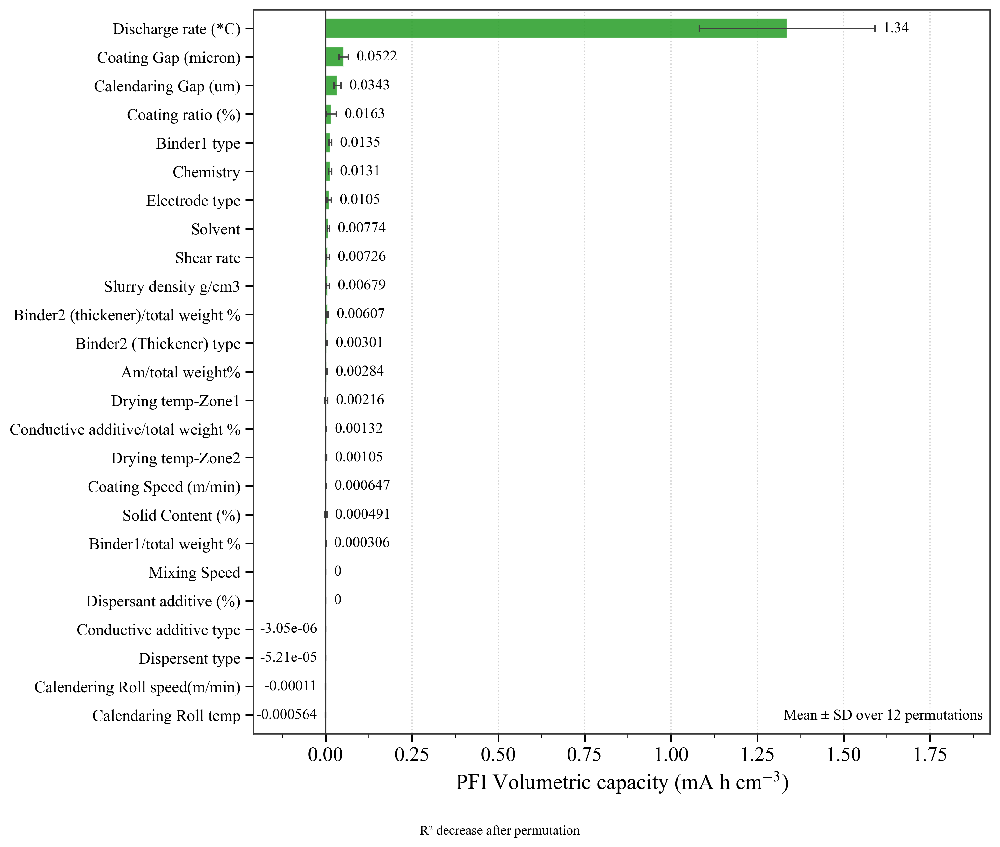

In [ ]:
PFI_INPUTS = df_input
PFI_TRUTH = df_input
PFI_TARGETS = [column for column in MEASURED_OUTPUTS if column in PFI_TRUTH]
PFI_FEATURES = rf_line.get_required_input_columns()
PFI_REPEATS = 12
PFI_SEED = 42
PFI_METRIC = "r2"                # or "rmse"
PFI_PLOT_TARGETS = [GRAVIMETRIC, VOLUMETRIC]

rf_pfi = rf_chain_pfi(rf_line, PFI_INPUTS, PFI_TRUTH, PFI_FEATURES, PFI_TARGETS,
                      repeats=PFI_REPEATS, seed=PFI_SEED, metric=PFI_METRIC)
export_table(rf_pfi, "importance/RF/pfi.csv")
display(rf_pfi.groupby("output", sort=False).head(5))
if SAVE_RESULTS:
    for output in PFI_PLOT_TARGETS:
        if output in PFI_TARGETS:
            show_saved_plot(importance_plot(rf_pfi, "mean_importance", output, "RF",
                "R² decrease after permutation" if PFI_METRIC == "r2" else "RMSE increase after permutation",
                error="std_importance"))


## 11. DNN whole-chain finite-difference importance

The original forward-difference convention is retained:
$$
rac{\partial y}{\partial x_j} pprox 
rac{y(x+h_j e_j)-y(x)}{h_j}.$$

Every stage is recomputed for every perturbed base input. Categorical inputs
stay fixed. Raw slopes have physical output/input units. The optional
`mean_absolute_one_sd` ranking multiplies mean absolute slopes by the reference
input SD so inputs have a common scale for each output. It is distinct from PFI.

Default steps are 0.1% of reference input SD with a minimum of 0.001 physical
units, to reduce float32 round-off. Change `FD_STEPS` and inspect step stability.


In [ ]:
import numpy as np

import pandas as pd

def finite_difference_sensitivity(line, frame, feature_cols, *, output_cols=None, epsilon=1e-4):
    if getattr(line, "family", None) != "DNN":
        raise ValueError("Finite-difference importance is assigned to the DNN chain only")
    inputs = chain_inputs(line, frame)
    output_cols = output_cols or OUTPUT_COLUMNS
    unknown = set(output_cols) - set(OUTPUT_COLUMNS)
    if unknown:
        raise ValueError(f"Unknown sensitivity outputs: {unknown}")
    baseline = simulate_without_feedback(line, inputs)
    records = []
    for feature in feature_cols:
        if feature not in inputs:
            raise KeyError(f"Sensitivity feature must be an original chain input: {feature}")
        if not pd.api.types.is_numeric_dtype(inputs[feature]):
            raise TypeError(f"Finite differences need numeric inputs: {feature}")
        step = float(epsilon[feature] if isinstance(epsilon, dict) else epsilon)
        if not np.isfinite(step) or step <= 0:
            raise ValueError(f"Positive finite epsilon required for {feature}")
        perturbed = inputs.copy()
        perturbed[feature] = perturbed[feature].astype(float) + step
        if not np.isfinite(perturbed[feature]).all():
            raise ValueError(f"Non-finite sensitivity input: {feature}")
        prediction = simulate_without_feedback(line, perturbed)
        for output in output_cols:
            derivatives = (prediction[output].to_numpy() - baseline[output].to_numpy()) / step
            for item, derivative in enumerate(derivatives):
                records.append({"chain": line.label, "item_index": item + 1,
                                "feature": feature, "output": output, "epsilon": step,
                                "input_value": float(inputs.iloc[item][feature]),
                                "base_output": float(baseline.iloc[item][output]),
                                "derivative": float(derivative)})
    return pd.DataFrame(records)

def summarise_sensitivity(detail, reference_inputs=None):
    """Signed/absolute slopes. These have units and are not RF score drops."""
    if detail.empty:
        return pd.DataFrame()
    grouped = detail.groupby(["chain", "output", "feature", "epsilon"], sort=False)
    summary = grouped["derivative"].agg(n="count", mean_signed="mean", std="std",
                                        minimum="min", maximum="max").reset_index()
    summary["mean_absolute"] = grouped["derivative"].apply(lambda d: d.abs().mean()).to_numpy()
    if reference_inputs is not None:
        scales = reference_inputs.select_dtypes("number").std(ddof=0)
        summary["reference_input_sd"] = summary["feature"].map(scales)
        summary["mean_absolute_one_sd"] = summary["mean_absolute"] * summary["reference_input_sd"]
    ranking = "mean_absolute_one_sd" if reference_inputs is not None else "mean_absolute"
    return summary.sort_values(["output", ranking], ascending=[True, False]).reset_index(drop=True)

def sensitivity_with_feedback(line, frame, feature_cols, **kwargs):
    """Original sequential sensitivities with zeta fixed during each item's probes."""
    if getattr(line, "family", None) != "DNN":
        raise ValueError("Finite-difference sensitivity is assigned to the DNN chain only")
    return line.sensitivity_items(chain_inputs(line, frame), feature_cols, use_feedback=True, **kwargs)


Change the sensitivity data, numeric features, targets and perturbation steps here.


,chain,output,feature,epsilon,n,mean_signed,std,minimum,maximum,mean_absolute,reference_input_sd,mean_absolute_one_sd
0,DNN,Calendered porosity (%),Calendaring Gap (um),0.013637,38,0.260789,0.100879,0.050208,0.386951,0.260789,13.637130,3.556416
1,DNN,Calendered porosity (%),Coating Gap (micron),0.036566,38,-0.039685,0.029314,-0.091637,0.017756,0.043423,36.565755,1.587808
2,DNN,Calendered porosity (%),Am/total weight%,0.008490,38,-0.130821,0.050829,-0.201294,-0.047592,0.130821,8.490263,1.110701
3,DNN,Calendered porosity (%),Calendering Roll speed(m/min),0.014388,38,-0.067802,0.025448,-0.115989,-0.023304,0.067802,14.387509,0.975500
4,DNN,Calendered porosity (%),Shear rate,0.065457,38,0.012993,0.018364,-0.005261,0.043982,0.014749,65.456514,0.965445
18,DNN,Calendered thickness (um),Calendaring Gap (um),0.013637,38,0.712127,0.187339,0.411777,0.949596,0.712127,13.637130,9.711370
19,DNN,Calendered thickness (um),Coating Gap (micron),0.036566,38,0.116995,0.038102,0.047168,0.168402,0.116995,36.565755,4.277993
20,DNN,Calendered thickness (um),Solid Content (%),0.008530,38,-0.303021,0.109071,-0.434280,-0.127065,0.303021,8.530081,2.584791
21,DNN,Calendered thickness (um),Shear rate,0.065457,38,-0.032300,0.049137,-0.132359,0.006581,0.035435,65.456514,2.319470
22,DNN,Calendered thickness (um),Am/total weight%,0.008490,38,-0.260274,0.151707,-0.487887,-0.069189,0.260274,8.490263,2.209798


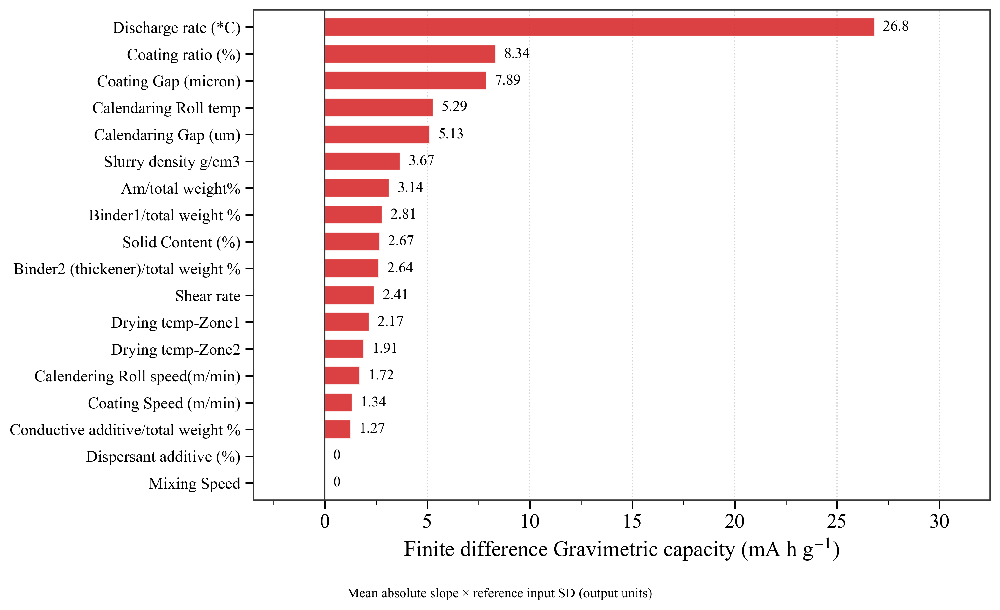

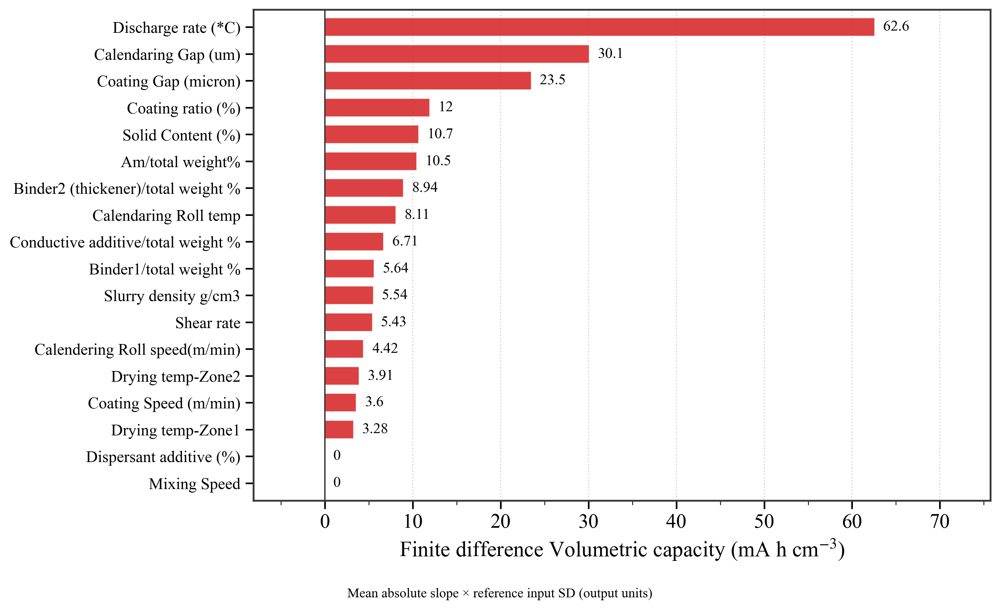

In [ ]:
FD_INPUTS = df_input
FD_FEATURES = list(chain_inputs(dnn_line, FD_INPUTS).select_dtypes("number").columns)
FD_TARGETS = OUTPUT_COLUMNS
FD_REFERENCE = chain_inputs(dnn_line, reference_data)
input_sd = FD_REFERENCE[FD_FEATURES].std(ddof=0)
FD_STEPS = {column: max(0.001, 0.001 * float(input_sd[column])) for column in FD_FEATURES}
# Override any step in physical input units, for example:
# FD_STEPS["Coating Gap (micron)"] = 0.01
FD_PLOT_TARGETS = [GRAVIMETRIC, VOLUMETRIC]

fd_detail = finite_difference_sensitivity(dnn_line, FD_INPUTS, FD_FEATURES,
                                           output_cols=FD_TARGETS, epsilon=FD_STEPS)
fd_summary = summarise_sensitivity(fd_detail, FD_REFERENCE)
export_table(fd_detail, "importance/DNN/finite_difference_detail.csv")
export_table(fd_summary, "importance/DNN/finite_difference_summary.csv")
display(fd_summary.groupby("output", sort=False).head(5))
if SAVE_RESULTS:
    for output in FD_PLOT_TARGETS:
        if output in FD_TARGETS:
            show_saved_plot(importance_plot(fd_summary, "mean_absolute_one_sd", output, "DNN",
                "Mean absolute slope × reference input SD (output units)"))


**Step stability.** Repeat the first few rows at half, original and double
steps. Inspect changes in the summary rather than assuming all small steps
are numerically reliable. No step is selected by fitting the measured outputs.


In [ ]:
STABILITY_ROWS = 10
STABILITY_MULTIPLIERS = [0.5, 1.0, 2.0]
STABILITY_TARGETS = [GRAVIMETRIC, VOLUMETRIC]
stability_tables = []
for multiplier in STABILITY_MULTIPLIERS:
    detail = finite_difference_sensitivity(dnn_line, FD_INPUTS.iloc[:STABILITY_ROWS], FD_FEATURES,
        output_cols=STABILITY_TARGETS, epsilon={c: step * multiplier for c, step in FD_STEPS.items()})
    summary = summarise_sensitivity(detail, FD_REFERENCE)
    summary["step_multiplier"] = multiplier
    stability_tables.append(summary)
step_stability = pd.concat(stability_tables, ignore_index=True)
export_table(step_stability, "importance/DNN/step_stability.csv")
display(step_stability.pivot_table(index=["output", "feature"], columns="step_multiplier",
                                   values="mean_absolute_one_sd"))


step_multiplier                                                          0.5  \
output                         feature                                         
Gravimetric capacity (mA h/g)  Am/total weight%                     3.114467   
                               Binder1/total weight %               1.937811   
                               Binder2 (thickener)/total weight %   2.373017   
                               Calendaring Gap (um)                 2.415259   
                               Calendaring Roll temp                3.280667   
                               Calendering Roll speed(m/min)        1.178479   
                               Coating Gap (micron)                 1.815269   
                               Coating Speed (m/min)                0.865855   
                               Coating ratio (%)                    7.499014   
                               Conductive additive/total weight %   1.240195   
                               Discharge rate (*C)                 28.393898   
                               Dispersant additive (%)              0.000000   
                               Drying temp-Zone1                    1.460284   
                               Drying temp-Zone2                    1.710974   
                               Mixing Speed                         0.000000   
                               Shear rate                           1.414127   
                               Slurry density g/cm3                 3.189181   
                               Solid Content (%)                    3.364920   
Volumetric capacity (mA h/cm3) Am/total weight%                    13.000149   
                               Binder1/total weight %               1.867003   
                               Binder2 (thickener)/total weight %   9.161318   
                               Calendaring Gap (um)                25.821039   
                               Calendaring Roll temp                3.278262   
                               Calendering Roll speed(m/min)        3.183067   
                               Coating Gap (micron)                15.140006   
                               Coating Speed (m/min)                2.733138   
                               Coating ratio (%)                   10.264575   
                               Conductive additive/total weight %   8.988069   
                               Discharge rate (*C)                 70.382576   
                               Dispersant additive (%)              0.000000   
                               Drying temp-Zone1                    1.877581   
                               Drying temp-Zone2                    4.276844   
                               Mixing Speed                         0.000000   
                               Shear rate                           4.429467   
                               Slurry density g/cm3                 4.231135   
                               Solid Content (%)                   11.064561   

step_multiplier                                                          1.0  \
output                         feature                                         
Gravimetric capacity (mA h/g)  Am/total weight%                     3.117963   
                               Binder1/total weight %               1.937474   
                               Binder2 (thickener)/total weight %   2.373721   
                               Calendaring Gap (um)                 2.416039   
                               Calendaring Roll temp                3.287887   
                               Calendering Roll speed(m/min)        1.175188   
                               Coating Gap (micron)                 1.807382   
                               Coating Speed (m/min)                0.863744   
                               Coating ratio (%)                    7.495944   
                               Conductive additive/total weight %   1.239692   

## 12. DNN sensitivity with delayed feedback

This calls the original sequential sensitivity method directly. For each item,
feedback memory stays fixed during its perturbations; after the baseline KPI
is read, memory is updated for the next item. The default is a short three-item
demonstration. Change its features, KPI, target, gain and scalar epsilon here.


In [ ]:
FEEDBACK_FD_FEATURES = ["Coating Gap (micron)", "Calendaring Gap (um)"]
FEEDBACK_FD_EPSILON = 0.01
FEEDBACK_FD_KPI = CAL_THICKNESS
FEEDBACK_FD_GAIN = -0.1
feedback_fd_inputs = pd.concat([chain_inputs(dnn_line, df_input).iloc[[0]]] * 3, ignore_index=True)
FEEDBACK_FD_TARGET = float(simulate_without_feedback(dnn_line, feedback_fd_inputs.iloc[[0]])
                          .iloc[0][FEEDBACK_FD_KPI]) + 2
feedback_fd_history = sensitivity_with_feedback(
    dnn_line, feedback_fd_inputs, FEEDBACK_FD_FEATURES,
    zeta_init={"CoatingDrying": {"delta_coating_gap": 0.0}},
    kpi_key=FEEDBACK_FD_KPI, kpi_target=FEEDBACK_FD_TARGET,
    feedback_gains={"CoatingDrying": {"delta_coating_gap": FEEDBACK_FD_GAIN}},
    feedback_stage_name="CoatingDrying", epsilon=FEEDBACK_FD_EPSILON)
feedback_fd_table = pd.DataFrame([
    {"item": record["item_index"], "KPI": record["J_base"], **record["dJ"],
     "memory_used": record["zeta_used"]["CoatingDrying"]["delta_coating_gap"],
     "memory_next": record["zeta_next"]["CoatingDrying"]["delta_coating_gap"]}
    for record in feedback_fd_history
])
export_table(feedback_fd_table, "importance/DNN/feedback_finite_differences.csv")
display(feedback_fd_table)


,item,KPI,Coating Gap (micron),Calendaring Gap (um),memory_used,memory_next
0,1,62.106213,0.168454,0.720015,0.000000,0.200000
1,2,62.129822,0.168517,0.719857,0.200000,0.397639
2,3,62.153072,0.167297,0.720733,0.397639,0.592953


## 13. Execution checks

These checks compare batched inference with the unchanged original sequential
core, verify that measured intermediate values cannot enter the chains, check
the feedback delay and update, and compare a real DNN finite-difference probe
with the original sensitivity implementation. They test execution consistency;
validation scores above quantify prediction accuracy.


In [ ]:
for family, line in chains.items():
    probe_inputs = chain_inputs(line, df_input).iloc[:3]
    batch = simulate_without_feedback(line, probe_inputs)
    sequential, _ = simulate_with_trace(line, probe_inputs)
    np.testing.assert_allclose(batch[OUTPUT_COLUMNS], sequential[OUTPUT_COLUMNS], rtol=2e-5, atol=2e-4)
    fake_truth = probe_inputs.copy()
    for column in OUTPUT_COLUMNS:
        fake_truth[column] = -999999.0
    no_leak = simulate_without_feedback(line, fake_truth)
    np.testing.assert_allclose(batch[OUTPUT_COLUMNS], no_leak[OUTPUT_COLUMNS], rtol=0, atol=0)
    trace = feedback_traces[family]
    np.testing.assert_allclose(trace.memory_used.iloc[1:], trace.memory_next.iloc[:-1])
    np.testing.assert_allclose(trace.memory_next,
                               trace.memory_used + FEEDBACK_GAIN * trace.error)

probe_feature = "Coating Gap (micron)"
probe_step = FD_STEPS[probe_feature] if probe_feature in FD_STEPS else 0.01
original_probe = dnn_line.sensitivity_one_item(
    chain_inputs(dnn_line, df_input).iloc[0].to_dict(),
    sensitivity_columns=[probe_feature], kpi_key=GRAVIMETRIC, epsilon=probe_step)
notebook_probe = finite_difference_sensitivity(dnn_line, df_input.iloc[[0]], [probe_feature],
                        output_cols=[GRAVIMETRIC], epsilon=probe_step)
np.testing.assert_allclose(notebook_probe.derivative.iloc[0],
                           original_probe["dJ"][probe_feature], rtol=1e-10, atol=1e-10)
print("Passed: RF/DNN batch versus original core; no measured-output leakage;")
print("one-item feedback delay and proportional update; DNN finite-difference agreement.")


Passed: RF/DNN batch versus original core; no measured-output leakage;
one-item feedback delay and proportional update; DNN finite-difference agreement.


## 14. Inverse analysis: alternative evaluated chain paths to a capacity target

Given the desired $(C_g,C_v)=(165\;\mathrm{mAh/g},480\;\mathrm{mAh/cm^3})$, retrieve paths satisfying **both** $|F_j(x,\zeta)-t_j|\leq\tau_j$. The tolerance is **±2% of each target**: ±3.3 mAh/g and ±9.6 mAh/cm³. Edit the percentage below; the physical-unit bands update automatically. This is a finite inverse analysis of evaluated candidates, not optimization or a claim to enumerate every physically possible path.

The background includes every current dataset execution, parametric test, active-feedback item, and held-feedback item. Each path retains its original input formulation, all eight predicted intermediate/final outputs, its source, and the actual feedback memory. The plots show one coating-gap axis using the input recipe. The feedback correction and the coating-stage gap actually used are retained only in diagnostic tables, so feedback paths remain traceable without duplicate plot axes. RF and DNN never exchange intermediate predictions. Duplicated input/memory paths remain in the grey background but are marked and excluded from the distinct-path results table.

Initially, successful paths must be NMC622 cathodes and pass the existing physical checks plus a positive applied coating gap and calculated porosity in 0-100%. These checks do not prove joint training support or experimental feasibility. Change `INVERSE_CONSTRAINTS` (a fixed value or a `(lower, upper)` tuple) and `INVERSE_REQUIRE_PHYSICAL` as needed. Target either model porosity or `CALCULATED_POROSITY` explicitly if you add that output.

Both figures share physical axis ranges calculated from **all evaluated paths in both families**. Grey lines provide the complete test background. Green highlights RF matches and red highlights DNN matches. The interactive HTML allows axis brushing and physical-value inspection; PNG/vector PDF provide static exports. If there are no hits, the plot stays grey and a separate nearest-evaluated table explains the gap. The nearest table never enlarges tolerances or labels a miss as success.

Run earlier sections first. To supply more paths, edit your input data or the parametric grid and rerun those evaluations and this section. No new models are fitted. Full path tables, selected alternatives, nearest evaluations, target settings and plots are saved in `codex_work/results/{RUN_LABEL}/inverse/`.


The capacity-axis ranges also include the requested tolerance intervals, even if no tested value reaches them. Blue marks show these intervals on static plots; interactive axis labels state the target and tolerance.


The axes follow the process: chemistry, active material %, viscosity, coating gap, coater speed, dry thickness, dry mass loading, roll gap, calendered thickness, porosity (calculated from mass and thickness), discharge rate, gravimetric capacity, and volumetric capacity. Model porosity remains available in the diagnostic comparisons; the inverse plot uses calculated porosity.


In [ ]:
def collect_evaluated_paths(family):
    """Retrieve existing evaluations, including the stage-local memory actually used."""
    frames = []
    sources = [("dataset", predictions[family], None),
               ("parametric", sweep_results[family], None),
               ("feedback active", feedback_results[family], feedback_traces[family].memory_used),
               ("feedback held", held_results[family],
                feedback_traces[family].held_coating_gap - feedback_items["Coating Gap (micron)"])]
    for source, result, memory in sources:
        data = result.reset_index(drop=True).copy()
        data["Source"] = source
        data["Source row"] = np.arange(1, len(data)+1)
        data["Feedback correction (µm)"] = 0.0 if memory is None else memory.to_numpy(float)
        data["Applied coating gap (µm)"] = data["Coating Gap (micron)"] + data["Feedback correction (µm)"]
        frames.append(data)
    data = pd.concat(frames, ignore_index=True)
    data["Path ID"] = [f"{family}-{i+1:04d}" for i in range(len(data))]
    data[CALCULATED_POROSITY] = geometry_porosity(data)[CALCULATED_POROSITY]
    # Mark repetitions; retain every evaluated test as requested for the background.
    key = chains[family].get_required_input_columns() + ["Feedback correction (µm)"]
    data["Repeated path"] = data.duplicated(key, keep="first")
    return data

def select_target_paths(data, targets, tolerances, constraints, require_physical=True):
    if not targets or set(targets) != set(tolerances):
        raise ValueError("Supply a target and tolerance for each requested output.")
    selected = pd.Series(True, index=data.index)
    distances = pd.DataFrame(index=data.index)
    for col, target in targets.items():
        tolerance = tolerances[col]
        if not np.isfinite([target, tolerance]).all() or tolerance <= 0:
            raise ValueError("Targets must be finite and tolerances positive.")
        distances[col] = (data[col] - target).abs() / tolerance
        selected &= distances[col].le(1) & np.isfinite(data[col])
    eligible = pd.Series(True, index=data.index)
    for col, value in constraints.items():
        if isinstance(value, tuple):
            eligible &= data[col].between(*value)
        else:
            eligible &= data[col].eq(value)
    if require_physical:
        eligible &= physical_checks(data).all_checks
        eligible &= data["Applied coating gap (\u00b5m)"].gt(0)
        eligible &= np.isfinite(data[CALCULATED_POROSITY]) & data[CALCULATED_POROSITY].between(0, 100)
    # Distance is a retrieval diagnostic, never an optimization objective.
    distance = distances.max(axis=1)
    selected &= eligible
    return selected, eligible, distance

def path_axis_specs(tables, columns):
    """Common physical ranges across both families, including the whole grey background."""
    combined = pd.concat(list(tables.values()), ignore_index=True)
    specs = {}
    for col in columns:
        if pd.api.types.is_numeric_dtype(combined[col]):
            finite = combined[col][np.isfinite(combined[col])]
            if finite.empty:
                raise ValueError(f"No finite values to plot: {col}")
            lo, hi = float(finite.min()), float(finite.max())
            if lo == hi:
                pad = max(abs(lo)*.02, .5)
                lo, hi = lo-pad, hi+pad
            # Include the requested interval even when it lies outside tested outputs.
            if col in INVERSE_TARGETS:
                lo = min(lo, INVERSE_TARGETS[col] - INVERSE_TOLERANCES[col])
                hi = max(hi, INVERSE_TARGETS[col] + INVERSE_TOLERANCES[col])
            ticks = np.linspace(lo, hi, 3)
            specs[col] = (lo, hi, None, ticks, [f"{t:.3g}" if abs(t) < 10 else f"{t:.1f}" for t in ticks])
        else:
            names = sorted(combined[col].astype(str).unique())
            mapping = {name: i for i, name in enumerate(names)}
            specs[col] = (-.25, max(len(names)-.75, .75), mapping,
                          list(mapping.values()), names)
    return specs

def plot_target_paths(data, selected, family, columns, specs):
    import plotly.graph_objects as go
    import textwrap
    # Draw successful paths last; all tested rows remain in the background.
    order = np.r_[np.flatnonzero(~selected.to_numpy()), np.flatnonzero(selected.to_numpy())]
    ordered, chosen = data.iloc[order], selected.iloc[order]
    dimensions, normalized = [], []
    labels = {
        "Chemistry": "Chemistry", "Coating Gap (micron)": "Coating gap (µm)",
        "Am/total weight%": "Active material (%)",
        "Coating Speed (m/min)": "Coater speed (m/min)",
        "Calendaring Gap (um)": "Roll gap (µm)", "Discharge rate (*C)": "Discharge rate (C)",
        VISCOSITY: "Viscosity (Pa s)", MASS: "Dry mass loading (mg/cm²)",
        DRY_THICKNESS: "Dry thickness (µm)", CAL_THICKNESS: "Calendered thickness (µm)",
        CAL_POROSITY: "Model porosity (%)", CALCULATED_POROSITY: "Porosity (%)",
        GRAVIMETRIC: "Gravimetric capacity (mAh/g)", VOLUMETRIC: "Volumetric capacity (mAh/cm³)",
    }
    for col in columns:
        lo, hi, mapping, ticks, texts = specs[col]
        values = ordered[col].astype(str).map(mapping).to_numpy(float) if mapping else ordered[col].to_numpy(float)
        normalized.append((values-lo)/(hi-lo))
        dimension = dict(label=labels.get(col, col), values=values, range=[lo, hi],
                         tickvals=list(ticks), ticktext=texts)
        if col in INVERSE_TARGETS:
            dimension["label"] += f" (target {INVERSE_TARGETS[col]:g} ± {INVERSE_TOLERANCES[col]:g})"
        dimensions.append(dimension)
    title = f"{family}: {int(selected.sum())} matching evaluations / {len(data)} tested paths"
    fig = go.Figure(go.Parcoords(dimensions=dimensions,
        line=dict(color=chosen.astype(int), cmin=0, cmax=1, showscale=False,
                  colorscale=[[0, '#c9c9c9'], [.499, '#c9c9c9'], [.5, CHART_COLORS[family]], [1, CHART_COLORS[family]]]),
        labelfont=dict(family="Times New Roman", size=12), tickfont=dict(size=11)))
    fig.update_layout(
                      height=680, width=max(1300, len(columns)*110),
                      margin=dict(l=85, r=85, t=150, b=60), paper_bgcolor="white")
    html = result_path(f"inverse/{family}/target_paths.html")
    fig.write_html(html, include_plotlyjs=True, auto_open=False)
    plt = _pyplot()
    matrix = np.array(normalized).T
    fig, ax = plt.subplots(figsize=(max(13, len(columns)*1.2), 7))
    x = np.arange(len(columns))
    for row, hit in zip(matrix, chosen):
        ax.plot(x, row, color=CHART_COLORS[family] if hit else '.75',
                alpha=.8 if hit else .18, lw=1.5 if hit else .65, zorder=3 if hit else 1)
    for i, col in enumerate(columns):
        lo, hi, _, ticks, texts = specs[col]
        if col in INVERSE_TARGETS:
            a = (INVERSE_TARGETS[col]-INVERSE_TOLERANCES[col]-lo)/(hi-lo)
            b = (INVERSE_TARGETS[col]+INVERSE_TOLERANCES[col]-lo)/(hi-lo)
            ax.fill_between([i-.065, i+.065], a, b, color=CHART_COLORS["Measured"],
                            alpha=.2, zorder=2)
            ax.text(i, 1.035, f"Target {INVERSE_TARGETS[col]:g} ± {INVERSE_TOLERANCES[col]:g}",
                    ha="center", va="bottom", fontsize=9, color=".2")
        ax.vlines(i, 0, 1, color='.4', lw=.85, zorder=4)
        for tick, text in zip(ticks, texts):
            y = (tick-lo)/(hi-lo)
            ax.plot([i-.025, i+.025], [y, y], color='.4', lw=.8, zorder=4)
            ax.text(i+.045, y, text, fontsize=9, ha='left', va='center', zorder=5,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=.8, pad=.2))
    ax.set_xticks(x, ['\n'.join(textwrap.wrap(labels.get(c,c), 19)) for c in columns], fontsize=11)
    ax.set_xlim(-.15, len(columns)-.6)
    ax.set_ylim(-.04, 1.07)
    ax.set_yticks([])
    ax.tick_params(axis='x', length=0, pad=14)
    for spine in ax.spines.values():
        spine.set_visible(False)
    caption = f"{family}: {int(selected.sum())} matches among {len(data)} evaluations. Shared physical axis ranges. Grey: all tests; colored: target matches; blue marks: target intervals."
    if not selected.any():
        caption += " No tested path satisfies every target condition."
    fig.text(.5, .02, caption, ha='center', fontsize=12)
    fig.tight_layout(rect=(0, .04, 1, 1))
    png = save_figure(fig, f"inverse/{family}/target_paths.png")
    plt.close(fig)
    return html, png


RF distinct target paths: 1


,Path ID,Source,Source row,Feedback correction (µm),Chemistry,Am/total weight%,Viscosity (Pa.s),Coating Gap (micron),Coating Speed (m/min),Dry Coating Thickness (µm),Mass loading dry (mg/cm2),Calendaring Gap (um),Calendered thickness (um),Calculated calendered porosity (%),Discharge rate (*C),Gravimetric capacity (mA h/g),Volumetric capacity (mA h/cm3)
9,RF-0010,dataset,10,0.0,NMC622,64.32,0.87271,113.0,1.0,70.75121,17.081956,57.156875,54.255605,30.651489,0.2,162.247422,479.687796


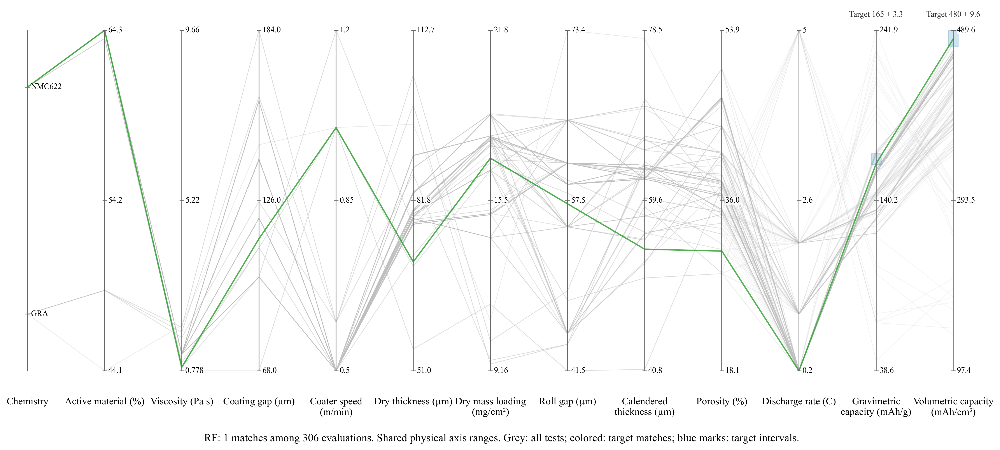

C:\Users\Tavako_M\OneDrive - University of Warwick\Workstation\BATTWIN Project\Paper1-Formal framework\New_upstream_models\Framework-level\codex_work\results\test_aggregated_deterministic\inverse\RF\target_paths.html

DNN distinct target paths: 0
No tested path meets BOTH capacity targets within the chosen tolerances.
Closest eligible evaluations below are diagnostics, not successful paths.


,Path ID,Source,Source row,Feedback correction (µm),Chemistry,Am/total weight%,Viscosity (Pa.s),Coating Gap (micron),Coating Speed (m/min),Dry Coating Thickness (µm),Mass loading dry (mg/cm2),Calendaring Gap (um),Calendered thickness (um),Calculated calendered porosity (%),Discharge rate (*C),Gravimetric capacity (mA h/g),Volumetric capacity (mA h/cm3),Maximum tolerance-normalized target distance
119,DNN-0120,parametric,82,0.0,NMC622,64.32,1.729090,160.0,0.5,111.180438,20.283720,45.000000,71.607663,37.607519,0.2,161.574580,474.532177,1.038006
8,DNN-0009,dataset,9,0.0,NMC622,64.32,1.694204,68.0,1.0,51.022508,13.298340,41.516754,40.806130,28.217896,0.2,161.867068,469.649100,1.078219
6,DNN-0007,dataset,7,0.0,NMC622,63.84,1.955349,110.0,1.0,65.273784,15.788018,48.093418,48.170926,27.808385,0.2,163.132845,469.173678,1.127742
9,DNN-0010,dataset,10,0.0,NMC622,64.32,1.936979,113.0,1.0,68.114385,17.672078,57.156875,57.157989,31.898791,0.2,162.574029,465.604875,1.499492
128,DNN-0129,parametric,91,0.0,NMC622,64.32,1.729090,160.0,0.5,98.882552,21.362478,45.000000,65.799180,28.488597,0.2,159.260898,483.927326,1.739122


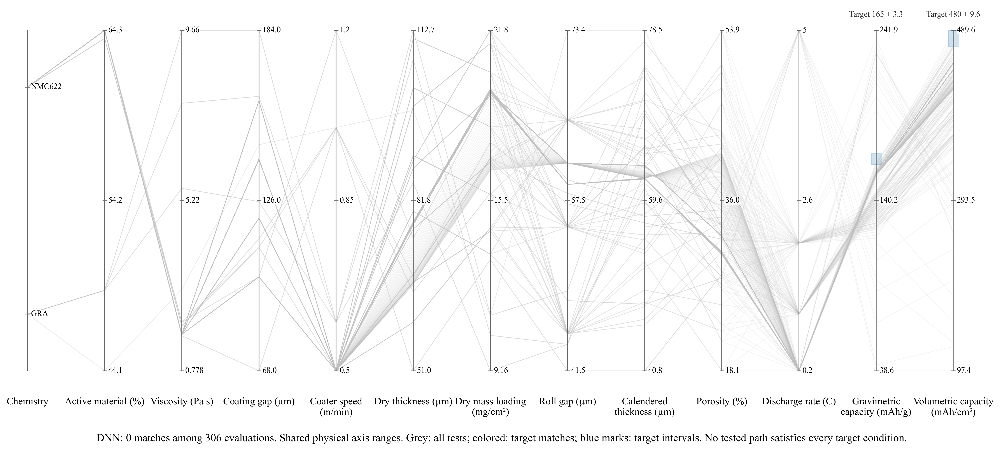

C:\Users\Tavako_M\OneDrive - University of Warwick\Workstation\BATTWIN Project\Paper1-Formal framework\New_upstream_models\Framework-level\codex_work\results\test_aggregated_deterministic\inverse\DNN\target_paths.html

,chain,evaluated_rows,unique_paths,matching_rows,unique_matching_paths,eligible_rows
0,RF,306,244,1,1,292
1,DNN,306,248,0,0,289


In [ ]:
# Initial NMC622 compromise suggested by the user; no optimization is performed.
INVERSE_TARGETS = {GRAVIMETRIC: 165.0, VOLUMETRIC: 480.0}
INVERSE_TOLERANCE_PERCENT = 2.0
INVERSE_TOLERANCES = {col: abs(target) * INVERSE_TOLERANCE_PERCENT / 100
                      for col, target in INVERSE_TARGETS.items()}
INVERSE_CONSTRAINTS = {"Electrode type": "Cathode", "Chemistry": "NMC622"}
INVERSE_REQUIRE_PHYSICAL = True
# Process order for the alternative-path figures; one coating-gap axis.
# Process order for the alternative-path figures; one coating-gap axis.
INVERSE_COLUMNS = ["Chemistry", "Am/total weight%", VISCOSITY,
                   "Coating Gap (micron)", "Coating Speed (m/min)",
                   DRY_THICKNESS, MASS, "Calendaring Gap (um)", CAL_THICKNESS,
                   CALCULATED_POROSITY, "Discharge rate (*C)",
                   GRAVIMETRIC, VOLUMETRIC]

inverse_paths = {family: collect_evaluated_paths(family) for family in chains}
inverse_specs = path_axis_specs(inverse_paths, INVERSE_COLUMNS)
inverse_matches, inverse_nearest, inverse_summary = {}, {}, []
for family, data in inverse_paths.items():
    selected, eligible, distance = select_target_paths(data, INVERSE_TARGETS,
        INVERSE_TOLERANCES, INVERSE_CONSTRAINTS, INVERSE_REQUIRE_PHYSICAL)
    data["Target match"] = selected
    data["Eligible under constraints"] = eligible
    data["Maximum tolerance-normalized target distance"] = distance
    inverse_matches[family] = data.loc[selected & ~data["Repeated path"]].copy()
    inverse_nearest[family] = data.loc[eligible & ~data["Repeated path"]].sort_values(
        "Maximum tolerance-normalized target distance").head(5)
    inverse_summary.append({"chain": family, "evaluated_rows": len(data),
        "unique_paths": int((~data["Repeated path"]).sum()), "matching_rows": int(selected.sum()),
        "unique_matching_paths": len(inverse_matches[family]), "eligible_rows": int(eligible.sum())})
    export_table(data, f"inverse/{family}/all_evaluated_paths.csv")
    export_table(inverse_matches[family], f"inverse/{family}/matching_paths.csv")
    export_table(inverse_nearest[family], f"inverse/{family}/nearest_evaluated_paths.csv")
    print(family, "distinct target paths:", len(inverse_matches[family]))
    shown = ["Path ID", "Source", "Source row", "Feedback correction (µm)"] + INVERSE_COLUMNS
    if len(inverse_matches[family]):
        display(inverse_matches[family][shown])
    else:
        print("No tested path meets BOTH capacity targets within the chosen tolerances.")
        print("Closest eligible evaluations below are diagnostics, not successful paths.")
        display(inverse_nearest[family][shown + ["Maximum tolerance-normalized target distance"]])
    if SAVE_RESULTS:
        html, png = plot_target_paths(data, selected, family, INVERSE_COLUMNS, inverse_specs)
        show_saved_plot(png)
        display(FileLink(str(html.relative_to(ROOT))))
inverse_summary = pd.DataFrame(inverse_summary)
display(inverse_summary)
export_table(inverse_summary, "inverse/summary.csv")
if SAVE_RESULTS:
    result_path("inverse/target_settings.json").write_text(json.dumps({
        "targets": INVERSE_TARGETS, "tolerances": INVERSE_TOLERANCES,
        "constraints": INVERSE_CONSTRAINTS, "require_physical": INVERSE_REQUIRE_PHYSICAL},
        indent=2), encoding="utf-8")


## Appendix. Original indexed mathematical implementation

The original indexed framework is preserved here as a separate namespace,
so its array-based feedback function cannot overwrite the named-store version.
This cell is optional for the ML experiments. Expand it to inspect the exact
`W_k`, `Pi_k`, state embedding, Jacobians and sensitivity propagation.
`IndexedStateSpaceLine` and `indexed_framework["get_jacobians"]` are available
after running it.


In [ ]:
indexed_framework = {}
indexed_source = '"""Original indexed orchestration and forward sensitivity mathematics, unchanged."""\n\nimport numpy as np\n\n\n# ============================================================\n# 1. NUMERICAL JACOBIANS\n# ------------------------------------------------------------\n# Used only when sensitivity analysis is turned on.\n#\n# Returns:\n#   J_r      = dM/dr\n#   J_theta  = dM/dtheta\n# ============================================================\n\ndef get_jacobians(func, r, u, theta, epsilon=1e-6):\n    """\n    Compute numerical Jacobians of a static stage model using\n    forward finite differences.\n\n    Parameters\n    ----------\n    func : callable\n        Stage model: y = func(r, u, theta)\n    r : np.ndarray\n        Local read vector\n    u : np.ndarray\n        Control vector\n    theta : np.ndarray\n        Local parameter vector\n    epsilon : float\n        Small perturbation for finite differences\n\n    Returns\n    -------\n    J_r : np.ndarray\n        Jacobian dM/dr with shape (dim_y, dim_r)\n    J_theta : np.ndarray\n        Jacobian dM/dtheta with shape (dim_y, dim_theta)\n    """\n    y_base = func(r, u, theta)\n    dim_y = len(y_base)\n\n    # Jacobian with respect to r\n    J_r = np.zeros((dim_y, len(r)))\n    for j in range(len(r)):\n        r_pert = r.copy()\n        r_pert[j] += epsilon\n        y_pert = func(r_pert, u, theta)\n        J_r[:, j] = (y_pert - y_base) / epsilon\n\n    # Jacobian with respect to theta\n    J_theta = np.zeros((dim_y, len(theta)))\n    for j in range(len(theta)):\n        theta_pert = theta.copy()\n        theta_pert[j] += epsilon\n        y_pert = func(r, u, theta_pert)\n        J_theta[:, j] = (y_pert - y_base) / epsilon\n\n    return J_r, J_theta\n\n\n# ============================================================\n# 2. FEEDBACK LAW\n# ------------------------------------------------------------\n# This is a simple proportional correction law.\n#\n# It updates the stage-specific feedback memory zeta_k based on\n# KPI error observed at the end of the chain.\n#\n# You can replace this later with any custom learning/controller law.\n# ============================================================\n\ndef proportional_feedback_update(zeta_list, error, gains, target_stage_idx=1):\n    """\n    Update feedback memory using a simple proportional law.\n\n    Parameters\n    ----------\n    zeta_list : list of np.ndarray\n        Current list of stage-specific feedback blocks:\n        [zeta_1, zeta_2, ..., zeta_N]\n    error : float\n        KPI deviation = KPI_current - KPI_target\n    gains : list of float\n        One gain per stage feedback block.\n        gains[k] is used to update zeta_k.\n    target_stage_idx : int\n        Index of stage to which correction is applied.\n        Default 1 means stage 2 in Python indexing convention.\n\n    Returns\n    -------\n    zeta_next : list of np.ndarray\n        Updated list of feedback blocks\n    """\n    zeta_next = [z.copy() for z in zeta_list]\n\n    # Only update the selected stage block if it exists and has dimension > 0\n    if len(zeta_next[target_stage_idx]) > 0:\n        zeta_next[target_stage_idx][0] += gains[target_stage_idx] * error\n\n    return zeta_next\n\n\n# ============================================================\n# 3. STATE-SPACE LINE CLASS\n# ------------------------------------------------------------\n# This class handles:\n#   - compiling the stage sequence\n#   - executing one item through the full line\n#   - executing multiple items with delayed feedback\n#   - optional sensitivity analysis\n#\n# The coding is intentionally kept simple and explicit.\n# ============================================================\n\nclass StateSpaceLine:\n    """\n    Static-map hybrid state-space framework with:\n      - global feature store eta\n      - stage-specific feedback memory zeta_k\n      - optional forward sensitivity propagation\n\n    Notes\n    -----\n    This implementation matches the simplified static-map framework:\n        y_k = M_k(r_k, u_k, theta_k)\n\n        r_k = W_k [eta ; zeta]\n\n        eta_k = (I - Pi_k) eta_{k-1} + Pi_k psi_k(y_k)\n\n    where psi_k is implemented as direct placement into a write slice.\n    """\n\n    def __init__(self, dim_eta_0, zeta_dims):\n        """\n        Parameters\n        ----------\n        dim_eta_0 : int\n            Dimension of the initial feature vector eta_0\n        zeta_dims : list of int\n            Dimensions of the stage-specific feedback blocks.\n            Example: [0, 1, 0, 0]\n        """\n        self.chain_def = []\n        self.dim_eta_0 = dim_eta_0\n        self.zeta_dims = zeta_dims\n        self.dim_zeta_total = sum(zeta_dims)\n        self.compiled = False\n\n    def load_sequence(self, chain_definition):\n        """\n        Load the ordered list of stage definitions.\n\n        Each stage is a dictionary with keys:\n            name         : stage name\n            func         : stage model function\n            read_indices : list of global feature indices or -1 for zeta_k access\n            out_dim      : dimension of stage output\n            u            : control vector\n            theta        : parameter vector\n        """\n        self.chain_def = chain_definition\n\n    def compile(self):\n        """\n        Compile the framework:\n          - total feature dimension P\n          - total parameter dimension p_theta\n          - read matrices W_k\n          - write masks Pi_k\n          - slices for output placement and parameter embedding\n        """\n        dim_P = self.dim_eta_0 + sum(stage["out_dim"] for stage in self.chain_def)\n        p_theta = sum(len(stage["theta"]) for stage in self.chain_def)\n\n        self.compiled_chain = []\n\n        current_write_idx = self.dim_eta_0\n        current_theta_idx = 0\n        current_zeta_idx = 0\n\n        for i, stage in enumerate(self.chain_def):\n            num_reads = len(stage["read_indices"])\n\n            # ----------------------------------------------------\n            # Build read selection matrix W_k\n            # W_k maps [eta ; zeta_flat] -> r_k\n            # ----------------------------------------------------\n            W_k = np.zeros((num_reads, dim_P + self.dim_zeta_total))\n\n            for local_idx, global_idx in enumerate(stage["read_indices"]):\n                if global_idx == -1:\n                    # Read from THIS stage\'s zeta block\n                    # For simplicity, this code assumes one feedback scalar\n                    # is read if the block exists.\n                    zeta_offset = dim_P + current_zeta_idx\n                    if self.zeta_dims[i] > 0:\n                        W_k[local_idx, zeta_offset] = 1.0\n                else:\n                    # Read from global eta\n                    W_k[local_idx, global_idx] = 1.0\n\n            # ----------------------------------------------------\n            # Build write mask Pi_k\n            # This stage writes into its dedicated output slice\n            # ----------------------------------------------------\n            mask = np.zeros(dim_P)\n            out_dim = stage["out_dim"]\n            mask[current_write_idx: current_write_idx + out_dim] = 1.0\n            Pi_k = np.diag(mask)\n\n            # Save compiled stage information\n            self.compiled_chain.append({\n                **stage,\n                "W_k": W_k,\n                "Pi_k": Pi_k,\n                "write_slice": slice(current_write_idx, current_write_idx + out_dim),\n                "theta_slice": slice(current_theta_idx, current_theta_idx + len(stage["theta"])),\n                "zeta_slice": slice(current_zeta_idx, current_zeta_idx + self.zeta_dims[i]),\n            })\n\n            current_write_idx += out_dim\n            current_theta_idx += len(stage["theta"])\n            current_zeta_idx += self.zeta_dims[i]\n\n        self.dim_P = dim_P\n        self.p_theta = p_theta\n        self.I = np.eye(dim_P)\n        self.compiled = True\n\n    # ========================================================\n    # Single-item execution\n    # --------------------------------------------------------\n    # This runs ONE item through the full line using the\n    # current feedback memory zeta.\n    #\n    # If calc_sensitivity=True, it also computes d(eta_N)/dtheta.\n    # ========================================================\n    def simulate_item(self, eta_0, zeta_list, calc_sensitivity=False):\n        """\n        Simulate one item through the process chain.\n\n        Parameters\n        ----------\n        eta_0 : np.ndarray\n            Initial feature vector (base product descriptor)\n        zeta_list : list of np.ndarray\n            Stage-specific feedback memory blocks\n        calc_sensitivity : bool\n            If True, compute forward sensitivity of eta_N wrt theta\n\n        Returns\n        -------\n        result : dict\n            {\n              "eta_final": final feature vector,\n              "zeta_flat": flattened feedback used in this run,\n              "stage_outputs": list of y_k,\n              "S_eta": d(eta_final)/dtheta or None\n            }\n        """\n        if not self.compiled:\n            raise RuntimeError("Framework must be compiled before simulation.")\n\n        # ----------------------------------------------------\n        # Initialize eta and flattened zeta\n        # ----------------------------------------------------\n        eta = np.zeros(self.dim_P)\n        eta[0:self.dim_eta_0] = eta_0\n\n        zeta_flat = np.concatenate(zeta_list) if self.dim_zeta_total > 0 else np.array([])\n\n        # ----------------------------------------------------\n        # Optional sensitivities\n        # ----------------------------------------------------\n        S_eta = np.zeros((self.dim_P, self.p_theta)) if calc_sensitivity else None\n\n        # zeta is treated as fixed input during a single chain execution\n        S_zeta = np.zeros((self.dim_zeta_total, self.p_theta)) if calc_sensitivity else None\n\n        stage_outputs = []\n\n        # ----------------------------------------------------\n        # Stage loop\n        # ----------------------------------------------------\n        for stage in self.compiled_chain:\n            # ---------- FORWARD ----------\n            global_state = np.concatenate([eta, zeta_flat])\n            r_k = stage["W_k"] @ global_state\n\n            y_k = stage["func"](\n                r_k,\n                np.asarray(stage["u"], dtype=float),\n                np.asarray(stage["theta"], dtype=float)\n            )\n\n            # Store stage output\n            stage_outputs.append(y_k.copy())\n\n            # eta update using write slice as the embedding psi_k\n            update_vec = np.zeros(self.dim_P)\n            update_vec[stage["write_slice"]] = y_k\n\n            # eta_k = (I - Pi_k) eta_{k-1} + Pi_k psi_k(y_k)\n            # Here Pi_k @ update_vec is equivalent to update_vec because\n            # update_vec is already zero outside the write slice.\n            eta = (self.I - stage["Pi_k"]) @ eta + update_vec\n\n            # ---------- SENSITIVITY ----------\n            if calc_sensitivity:\n                J_r, J_theta_local = get_jacobians(\n                    stage["func"],\n                    r_k,\n                    np.asarray(stage["u"], dtype=float),\n                    np.asarray(stage["theta"], dtype=float)\n                )\n\n                # Expand local theta Jacobian to global theta space\n                J_theta_global = np.zeros((len(y_k), self.p_theta))\n                J_theta_global[:, stage["theta_slice"]] = J_theta_local\n\n                # S_rk = W_k [S_eta ; S_zeta]\n                S_global = np.vstack((S_eta, S_zeta))\n                S_rk = stage["W_k"] @ S_global\n\n                # S_yk = J_r * S_rk + J_theta_global\n                S_yk = J_r @ S_rk + J_theta_global\n\n                # Embed S_yk into global eta sensitivity\n                S_update = np.zeros((self.dim_P, self.p_theta))\n                S_update[stage["write_slice"], :] = S_yk\n\n                # S_eta update\n                S_eta = (self.I - stage["Pi_k"]) @ S_eta + S_update\n\n        return {\n            "eta_final": eta,\n            "zeta_flat": zeta_flat,\n            "stage_outputs": stage_outputs,\n            "S_eta": S_eta\n        }\n\n    # ========================================================\n    # Multi-item execution with delayed feedback\n    # --------------------------------------------------------\n    # This runs several items sequentially.\n    # After each item completes:\n    #   - a KPI is read\n    #   - deviation from target is computed\n    #   - zeta is updated for the NEXT item\n    # ========================================================\n    def simulate_items(\n        self,\n        num_items,\n        eta_0,\n        zeta_init,\n        kpi_stage_index,\n        kpi_output_index,\n        kpi_target,\n        feedback_gains,\n        feedback_stage_index=1,\n        calc_sensitivity=False\n    ):\n        """\n        Simulate multiple items with one-step delayed feedback.\n\n        Parameters\n        ----------\n        num_items : int\n            Number of items / chain executions\n        eta_0 : np.ndarray\n            Initial base feature vector for each item\n        zeta_init : list of np.ndarray\n            Initial stage-specific feedback blocks\n        kpi_stage_index : int\n            Which stage output contains the KPI\n        kpi_output_index : int\n            Which component of that stage output is the KPI\n        kpi_target : float\n            Desired target KPI value\n        feedback_gains : list of float\n            Gain list for stage-specific feedback update\n        feedback_stage_index : int\n            Which stage zeta_k gets updated by the feedback law\n        calc_sensitivity : bool\n            If True, compute d(eta_N)/dtheta for each item\n\n        Returns\n        -------\n        history : list of dict\n            One record per item containing outputs, KPI, error, eta_final, etc.\n        """\n        if not self.compiled:\n            raise RuntimeError("Framework must be compiled before simulation.")\n\n        zeta_current = [z.copy() for z in zeta_init]\n        history = []\n\n        for i in range(num_items):\n            # Run one item using current zeta^i\n            result = self.simulate_item(\n                eta_0=eta_0,\n                zeta_list=zeta_current,\n                calc_sensitivity=calc_sensitivity\n            )\n\n            eta_final = result["eta_final"]\n            stage_outputs = result["stage_outputs"]\n            S_eta = result["S_eta"]\n\n            # ------------------------------------------------\n            # Compute KPI and deviation\n            # ------------------------------------------------\n            kpi_value = stage_outputs[kpi_stage_index][kpi_output_index]\n            error = kpi_value - kpi_target\n\n            # ------------------------------------------------\n            # Update feedback memory for NEXT item\n            # ------------------------------------------------\n            zeta_next = proportional_feedback_update(\n                zeta_list=zeta_current,\n                error=error,\n                gains=feedback_gains,\n                target_stage_idx=feedback_stage_index\n            )\n\n            # Save history for inspection\n            history.append({\n                "item_index": i + 1,\n                "eta_final": eta_final.copy(),\n                "stage_outputs": [y.copy() for y in stage_outputs],\n                "kpi_value": float(kpi_value),\n                "kpi_target": float(kpi_target),\n                "error": float(error),\n                "zeta_used": [z.copy() for z in zeta_current],\n                "zeta_next": [z.copy() for z in zeta_next],\n                "S_eta": None if S_eta is None else S_eta.copy()\n            })\n\n            # Shift zeta forward by one step\n            zeta_current = zeta_next\n\n        return history'
exec(indexed_source, indexed_framework)
IndexedStateSpaceLine = indexed_framework["StateSpaceLine"]
